# CS221 Mini Projects — Programming Part

**Course:** Artificial Intelligence: Principles and Techniques (based on Stanford CS221, Spring 2026 coursework)
**Deliverables:** each team uploads to Moodle **one notebook** (this file, executed with all outputs, for the programming part)
and **one PDF** (`report/report.pdf`, for the theoretical part). Both use the same numbering.
**Deadline:** 5 December 2026 · **Presentations:** 14–19 December 2026 (Zoom)

## Team Members

| # | Full name | Student Number | Registration Number |
|---|-----------|----------------|---------------------|
| 1 | MUJUNI INNOCENT | 2400707155 | 24/U/07155/PS |
| 2 | ROLAND EMMA WATEGA | 2500702744 | 25/U/02744/PS |
| 3 | RAN BINQI | 2500730559 | 25/X/30559/PS |
| 4 | WERE EZRA CHRISTIAN | 2500702746 | 25/U/02746/PS |
| 5 | KASAJJA ALVIN ANTHONY | 2500729485 | 25/U/29485/PS |
| 6 | BYARUGABA JOHN KEITH | 2500703728 | 25/U/03728/PS |
| 7 | ATINO EMILY | 2500700236 | 25/U/0236 |

**Team:** Group 13

> Keep this table identical to `report/team.tex`.

## Contents

| No. | Assignment | Programming problems in this notebook | Code folder |
|-----|------------|----------------------------------------|-------------|
| 1 | Foundations | 4a–4f (Python warm-up functions) | `assignments/01_foundations` |
| 2 | Sentiment Classification | 3a–3e (linear classifier, SGD, n-grams), 5b (k-means) | `assignments/02_sentiment` |
| 3 | Route Planning | 2a–2b, 3a & 3c (search problems), 4a–4c (A\*) | `assignments/03_route` |
| 4 | Controlling MountainCar | 3a–3c (value iteration), 4a–4d (Q-learning), 5c (constrained RL) | `assignments/04_mountaincar` |
| 5 | Pac-Man | 1b (minimax), 2a (alpha-beta), 3b (expectimax), 4a (evaluation, extra credit) | `assignments/05_pacman` |
| 6 | Bayesian Networks (Car Tracking) | 1c (observe), 2c (elapseTime), 4b (sensor deception) | `assignments/06_bayesian` |
| 7 | From Language to Logic | 1a–1c, 2a–2d, 3a, 4a, 5a–5c (extra credit) | `assignments/07_logic` |

Written / theoretical answers for every assignment are in the PDF report, which uses the same numbering.

### How this notebook is organised

* Each assignment's implementation lives in `assignments/<NN_name>/submission.py`. That is the
  starter file the official grader imports, and the only file the course staff ask us to modify.
* For each programming problem the notebook (1) states the task, (2) explains our approach,
  (3) displays the documented source with `show_source`, (4) runs the official tests, and
  (5) where the problem asks for it, runs experiments and saves figures into `report/figures/`.
* `cs221_helpers.py` isolates the seven starter codebases from each other: several of them
  use the same module names (`util`, `submission`, `grader`).

In [1]:
# Notebook setup: shared helpers + environment check (the graders expect Python 3.12).
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))          # the notebook folder holds cs221_helpers.py
from cs221_helpers import (ASSIGNMENTS, use_assignment, load, run_grader, run_script,
                           show_source, environment_report, REPO_ROOT)

environment_report()

Python 3.12.10  (D:\cs\ai\Min-Project-Assignments\.venv\Scripts\python.exe)
  numpy       1.26.4


  matplotlib  3.11.2
  gymnasium   0.28.1
  pygame      2.5.2
  osmium      compiled package unavailable -> using notebook/fallback/osmium (pure Python)
  plotly      7.1.0


  pandas      3.0.6
  tkinter     available


---
# Assignment 1: Foundations

Warm-up in optimisation, probability, complexity and ethics. Problems 1–3 are written (PDF §1).
**Problem 4** asks for six short Python functions, using **standard library only, no numpy**.
These helpers (sparse vectors in particular) come back in later assignments.

In [2]:
# Activate Assignment 1: imports and relative file paths now resolve inside its folder.
hw = use_assignment(1)
sub = load("submission")

Active: Assignment 1 - Foundations  (assignments\01_foundations)


## 1.4a — find_alphabetically_first_word

**Task.** Return the lexicographically smallest word of a string (words = whitespace-separated).

**Approach.** `str.split()` yields the maximal whitespace-free chunks; Python's `min` over strings is the case-sensitive lexicographic order the problem asks for. $O(\text{len})$.

In [3]:
show_source(sub.find_alphabetically_first_word)

def find_alphabetically_first_word(text: str) -> str:
    """
    Given a string |text|, return the word in |text| that comes first
    lexicographically (i.e., the word that would come first after sorting).
    A word is defined by a maximal sequence of characters without whitespaces.
    Words are case sensitive -- i.e. we may not assume that letters are all in lowercase.
    You might find min() handy here. If the input text is an empty string,
    it is acceptable to either return an empty string or throw an error.
    """
    # BEGIN_SOLUTION
    # str.split() with no argument splits on runs of any whitespace, so each
    # element is exactly one "maximal sequence of characters without whitespace".
    # Python compares strings lexicographically by code point, which is the
    # case-sensitive order the problem asks for ('Z' < 'a').
    words = text.split()
    return min(words) if words else ''
    # END_SOLUTION

In [4]:
run_grader(1, '4a-0-basic', '4a-1-basic', '4a-2-basic')

========== START GRADING
----- START PART 4a-0-basic: simple test case
----- END PART 4a-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-1-basic: simple test case
----- END PART 4a-1-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-2-basic: big test case
----- END PART 4a-2-basic [took 0:00:00.011528 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 1.4b — euclidean_distance

**Task.** Euclidean distance between two 2-D points.

**Approach.** `math.hypot(dx, dy)` is $\sqrt{dx^2+dy^2}$ with better numerical care than squaring by hand.

In [5]:
show_source(sub.euclidean_distance)

def euclidean_distance(loc1: Position, loc2: Position) -> float:
    """
    Return the Euclidean distance between two locations, where the locations
    are pairs of numbers (e.g., (3, 5)).
    """
    # BEGIN_SOLUTION
    # sqrt((x1 - x2)^2 + (y1 - y2)^2); math.hypot computes exactly this and is
    # numerically more careful than squaring by hand.
    (x1, y1), (x2, y2) = loc1, loc2
    return math.hypot(x1 - x2, y1 - y2)
    # END_SOLUTION

In [6]:
run_grader(1, '4b-0-basic')

========== START GRADING
----- START PART 4b-0-basic: simple test case
----- END PART 4b-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 1.4c — mutate_sentences

**Task.** All sentences of the same length whose adjacent word pairs all appear adjacent in the original sentence.

**Approach.** Build a graph `successors[w]` = words that directly follow `w` in the original sentence. A similar sentence is exactly a walk of the same length in this graph, so we run a depth-first search from every distinct word and collect completed walks in a `set` (which also removes duplicates).

In [7]:
show_source(sub.mutate_sentences)

def mutate_sentences(sentence: str) -> List[str]:
    """
    Given a sentence (sequence of words), return a list of all "similar"
    sentences.
    We define a sentence to be "similar" to the original sentence if
      - it has the same number of words, and
      - each pair of adjacent words in the new sentence also occurs in the
        original sentence (the words within each pair should appear in the same
        order in the output sentence as they did in the original sentence).
    Notes:
      - The order of the sentences you output doesn't matter.
      - You must not output duplicates.
      - Your generated sentence can use a word in the original sentence more
        than once.
    Example:
      - Input: 'the cat and the mouse'
      - Output: ['and the cat and the', 'the cat and the mouse',
                 'the cat and the cat', 'cat and the cat and']
                (Reordered versions of this list are allowed.)
    """
    # BEGIN_SOLUTION
    words = sentence.split()
    length = len(words)

    # Build the "allowed transitions" graph: successors[w] is the set of words
    # that directly follow w somewhere in the original sentence. A similar
    # sentence is exactly a walk of `length` words in this graph.
    successors = collections.defaultdict(set)
    for current_word, next_word in zip(words, words[1:]):
        successors[current_word].add(next_word)

    results = set()  # a set removes duplicate walks automatically

    def extend(path: List[str]) -> None:
        """Depth-first extension of a partial walk until it has `length` words."""
        if len(path) == length:
            results.add(' '.join(path))
            return
        for next_word in successors[path[-1]]:
            extend(path + [next_word])

    # A walk may start at any distinct word of the sentence.
    for start_word in set(words):
        extend([start_word])
    return list(results)
    # END_SOLUTION

In [8]:
run_grader(1, '4c-0-basic')

========== START GRADING
----- START PART 4c-0-basic: simple test
----- END PART 4c-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 1.4d — sparse_vector_dot_product

**Task.** Dot product of two sparse vectors represented as `collections.defaultdict(float)`.

**Approach.** Only keys present in *both* vectors contribute, so iterate over the smaller dict and `.get()` the key in the larger one (indexing a `defaultdict` would insert zeros as a side effect). $O(\min(|v_1|,|v_2|))$.

In [9]:
show_source(sub.sparse_vector_dot_product)

def sparse_vector_dot_product(v1: SparseVector, v2: SparseVector) -> float:
    """
    Given two sparse vectors (vectors where most of the elements are zeros)
    |v1| and |v2|, each represented as collections.defaultdict(float), return
    their dot product.

    You might find it useful to use sum() and a list comprehension.
    This function will be useful later for linear classifiers.
    Note: A sparse vector has most of its entries as 0.
    """
    # BEGIN_SOLUTION
    # Only keys present in BOTH vectors contribute, so iterate over the smaller
    # vector and look the key up in the larger one. Use .get() rather than
    # indexing: indexing a defaultdict would insert zero entries as a side effect.
    if len(v1) > len(v2):
        v1, v2 = v2, v1
    return sum(value * v2.get(key, 0.0) for key, value in v1.items())
    # END_SOLUTION

In [10]:
run_grader(1, '4d-0-basic')

========== START GRADING
----- START PART 4d-0-basic: simple test
----- END PART 4d-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 1.4e — increment_sparse_vector

**Task.** In-place `v1 += scale * v2` for sparse vectors.

**Approach.** Walk the keys of `v2` and add `scale * value` into `v1` in place; keys only in `v1` are untouched because `scale * 0` adds nothing. `v2` is never modified.

In [11]:
show_source(sub.increment_sparse_vector)

def increment_sparse_vector(v1: SparseVector, scale: float, v2: SparseVector,
) -> None:
    """
    Given two sparse vectors |v1| and |v2|, perform v1 += scale * v2.
    If the scale is zero, you are allowed to modify v1 to include any
    additional keys in v2, or just not add the new keys at all.

    NOTE: This function should MODIFY v1 in-place, but not return it.
    Do not modify v2 in your implementation.
    This function will be useful later for linear classifiers.
    """
    # BEGIN_SOLUTION
    # Every key of v2 touches v1; keys of v1 that are absent from v2 stay as
    # they are (scale * 0 adds nothing). .get() keeps this correct even if v1
    # is a plain dict rather than a defaultdict.
    for key, value in v2.items():
        v1[key] = v1.get(key, 0.0) + scale * value
    # END_SOLUTION

In [12]:
run_grader(1, '4e-0-basic')

========== START GRADING
----- START PART 4e-0-basic: simple test
----- END PART 4e-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 1.4f — find_nonsingleton_words

**Task.** Set of words that occur more than once in a text.

**Approach.** One `collections.Counter` pass over the words, then keep those with count $> 1$. $O(\text{len})$.

In [13]:
show_source(sub.find_nonsingleton_words)

def find_nonsingleton_words(text: str) -> Set[str]:
    """
    Split the string |text| by whitespace and return the set of words that
    occur more than once.
    You might find it useful to use collections.defaultdict(int).
    """
    # BEGIN_SOLUTION
    # Count every word in one pass, then keep the words seen at least twice.
    counts = collections.Counter(text.split())
    return {word for word, count in counts.items() if count > 1}
    # END_SOLUTION

In [14]:
run_grader(1, '4f-0-basic')

========== START GRADING
----- START PART 4f-0-basic: simple test
----- END PART 4f-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

### Assignment 1: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [15]:
run_grader(1)

========== START GRADING
----- START PART 4a-0-basic: simple test case
----- END PART 4a-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

----- START PART 4a-1-basic: simple test case
----- END PART 4a-1-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

----- START PART 4a-2-basic: big test case
----- END PART 4a-2-basic [took 0:00:00.021049 (max allowed 5 seconds), 1/1 points]

----- START PART 4b-0-basic: simple test case
----- END PART 4b-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

----- START PART 4b-1-hidden: 100 random trials
----- END PART 4b-1-hidden [took 0:00:00 (max allowed 5 seconds), ???/2 points (hidden test ungraded)]

----- START PART 4c-0-basic: simple test
----- END PART 4c-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

----- START PART 4c-1-hidden: random trials
----- END PART 4c-1-hidden [took 0:00:00 (max allowed 5 seconds), ???/2 points (hidden test ungraded)]

----- START PART 4c-2-hidden: random trials (bigger)
---

0

---
# Assignment 2: Sentiment Classification

Linear classification of Rotten-Tomatoes reviews with hinge loss + SGD, character n-gram features,
and k-means. Problems 1, 2, 4 and the written parts of 3e/5a/5c are in PDF §2.
**No numpy/sklearn**: use `util.dot_product` / `util.increment` on dict feature vectors.
Targets: **< 4 % train error** and **< 30 % validation error**.

In [16]:
# Activate Assignment 2: imports and relative file paths now resolve inside its folder.
hw = use_assignment(2)
sub = load("submission")

Active: Assignment 2 - Sentiment Classification  (assignments\02_sentiment)


## 2.3a — extract_word_features

**Task.** Map a review to a word-count feature vector φ(x) (dict).

**Approach.** A plain dictionary of word counts; words are split on whitespace and are case sensitive, as the handout specifies. This is $\phi(x)$ for the rest of the problem.

In [17]:
show_source(sub.extract_word_features)

def extract_word_features(x: str) -> FeatureVector:
    """
    Extract word features for a string x. Words are delimited by
    whitespace characters only.
    @param string x:
    @return dict: feature vector representation of x.
    Example: "I am what I am" --> {'I': 2, 'am': 2, 'what': 1}
    """
    # BEGIN_YOUR_CODE
    # phi(x) maps each word to its number of occurrences. str.split() with no
    # argument splits on any run of whitespace; words differing only in case
    # ("great" vs "Great") are deliberately kept as different features.
    features: FeatureVector = {}
    for word in x.split():
        features[word] = features.get(word, 0) + 1
    return features
    # END_YOUR_CODE

In [18]:
run_grader(2, '3a-0-basic')

========== START GRADING
----- START PART 3a-0-basic: basic test
----- END PART 3a-0-basic [took 0:00:00 (max allowed 1 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 2.3b — learn_predictor (SGD on hinge loss)

**Task.** Learn weights with SGD on hinge loss; print train/validation error each epoch.

**Approach.** Stochastic gradient descent on the hinge loss $\max(0, 1 - (\mathbf{w}\cdot\phi(x))\,y)$. Its gradient is $-y\,\phi(x)$ when the margin is below 1 and $0$ otherwise, so each step is `increment(w, eta*y, phi)` only on margin violations. Features are extracted **once** (not once per epoch), and after every epoch we print train/validation error. Reaches 2.8% train / 27.4% validation error (targets < 4% / < 30%).

In [19]:
show_source(sub.learn_predictor)

def learn_predictor(train_examples: List[Tuple[T, int]],
                   validation_examples: List[Tuple[T, int]],
                   feature_extractor: Callable[[T], FeatureVector],
                   num_epochs: int, eta: float) -> WeightVector:
    '''
    Given |train_examples| and |validation_examples| (each one is a list of (x,y)
    pairs), a |feature_extractor| to apply to x, and the number of epochs to
    train |num_epochs|, the step size |eta|, return the weight vector (sparse
    feature vector) learned.

    You should implement stochastic gradient descent.

    Notes:
    - Only use the train_examples for training!
    - You should call evaluate_predictor() on both train_examples and
      validation_examples to see how you're doing as you learn after each epoch.
    - The predictor should output +1 if the score is precisely 0.
    '''
    weights: WeightVector = {}

    # BEGIN_YOUR_CODE
    # Feature extraction is the expensive part, so do it once per example instead
    # of once per epoch. We train on train_features only; validation_features is
    # used purely to report progress.
    train_features = [(feature_extractor(x), y) for x, y in train_examples]
    validation_features = [(feature_extractor(x), y) for x, y in validation_examples]

    def predict(phi: FeatureVector) -> int:
        """sign(w . phi(x)), with the required convention that a score of 0 is +1."""
        return 1 if dot_product(weights, phi) >= 0 else -1

    for epoch in range(num_epochs):
        for phi, y in train_features:
            # Hinge loss: max(0, 1 - (w . phi) y). Its gradient w.r.t. w is
            # -y * phi when the margin (w . phi) y is below 1, and 0 otherwise,
            # so the SGD step w <- w - eta * grad only fires on margin violations.
            margin = dot_product(weights, phi) * y
            if margin < 1:
                increment(weights, eta * y, phi)

        train_error = evaluate_predictor(train_features, predict)
        validation_error = evaluate_predictor(validation_features, predict)
        print(f"epoch {epoch + 1:2d}: train error = {train_error:.4f}, "
              f"validation error = {validation_error:.4f}")
    # END_YOUR_CODE
    return weights

In [20]:
run_grader(2, '3b-0-basic', '3b-1-basic', '3b-2-basic')

========== START GRADING
----- START PART 3b-0-basic: basic sanity check for learning correct weights on two training and testing examples each
epoch  1: train error = 0.0000, validation error = 0.0000
epoch  2: train error = 0.0000, validation error = 0.0000
epoch  3: train error = 0.0000, validation error = 0.0000
epoch  4: train error = 0.0000, validation error = 0.0000
epoch  5: train error = 0.0000, validation error = 0.0000
epoch  6: train error = 0.0000, validation error = 0.0000
epoch  7: train error = 0.0000, validation error = 0.0000
epoch  8: train error = 0.0000, validation error = 0.0000
epoch  9: train error = 0.0000, validation error = 0.0000
epoch 10: train error = 0.0000, validation error = 0.0000
epoch 11: train error = 0.0000, validation error = 0.0000
epoch 12: train error = 0.0000, validation error = 0.0000
epoch 13: train error = 0.0000, validation error = 0.0000
epoch 14: train error = 0.0000, validation error = 0.0000
epoch 15: train error = 0.0000, validation e

========== START GRADING
----- START PART 3b-1-basic: test correct overriding of positive weight due to one negative instance with repeated words
epoch  1: train error = 0.0000, validation error = 0.0000
epoch  2: train error = 0.0000, validation error = 0.0000
epoch  3: train error = 0.0000, validation error = 0.0000
epoch  4: train error = 0.0000, validation error = 0.0000
epoch  5: train error = 0.0000, validation error = 0.0000
epoch  6: train error = 0.0000, validation error = 0.0000
epoch  7: train error = 0.0000, validation error = 0.0000
epoch  8: train error = 0.0000, validation error = 0.0000
epoch  9: train error = 0.0000, validation error = 0.0000
epoch 10: train error = 0.0000, validation error = 0.0000
epoch 11: train error = 0.5000, validation error = 0.0000
epoch 12: train error = 0.5000, validation error = 0.0000
epoch 13: train error = 0.5000, validation error = 0.0000
epoch 14: train error = 0.5000, validation error = 0.0000
epoch 15: train error = 0.0000, validation

========== START GRADING
----- START PART 3b-2-basic: test classifier on real polarity dev dataset
Read 3554 examples from polarity.train
Read 3554 examples from polarity.dev
epoch  1: train error = 0.2895, validation error = 0.3509
epoch  2: train error = 0.2186, validation error = 0.3213
epoch  3: train error = 0.1784, validation error = 0.3134
epoch  4: train error = 0.1508, validation error = 0.3039
epoch  5: train error = 0.1289, validation error = 0.2932
epoch  6: train error = 0.1114, validation error = 0.2884
epoch  7: train error = 0.0965, validation error = 0.2870
epoch  8: train error = 0.0872, validation error = 0.2783
epoch  9: train error = 0.0808, validation error = 0.2822
epoch 10: train error = 0.0675, validation error = 0.2797
epoch 11: train error = 0.0639, validation error = 0.2800
epoch 12: train error = 0.0580, validation error = 0.2780
epoch 13: train error = 0.0492, validation error = 0.2772
epoch 14: train error = 0.0487, validation error = 0.2772
epoch 15: tra

0

## 2.3c — generate_dataset

**Task.** Generate synthetic examples whose label is the sign of w·φ(x), to sanity-check the learner.

**Approach.** Pick a random non-empty subset of the weight vector's features with random small counts as $\phi(x)$, then label it with the given classifier ($y = +1$ when the score is $\ge 0$), so every example is correct by construction. Used to sanity-check `learn_predictor` with the identity feature extractor.

In [21]:
show_source(sub.generate_dataset)

def generate_dataset(num_examples: int, weights: WeightVector) -> List[Example]:
    '''
    Return a set of examples (phi(x), y) randomly which are classified
      correctly by |weights|.
    '''
    random.seed(42)

    # Return a single example (phi(x), y).
    # phi(x) should be a dict whose keys are a subset of the keys in weights
    # and values can be anything (randomize!) with a score for the given weight vector.
    # note that there is intentionally flexibility in how you define phi.
    # y should be 1 or -1 as classified by the weight vector.
    # IMPORTANT: In the case that the score is 0, y should be set to 1.

    # Note that the weight vector can be arbitrary during testing.
    def generate_example() -> Tuple[Dict[str, int], int]:
        # BEGIN_YOUR_CODE
        # Pick a random non-empty subset of the weight vector's features and give
        # each a random small integer count; this plays the role of phi(x).
        feature_names = list(weights.keys())
        num_features = random.randint(1, len(feature_names)) if feature_names else 0
        phi = {name: random.randint(1, 5)
               for name in random.sample(feature_names, num_features)}
        # Label the example with the classifier defined by `weights`, so that by
        # construction it is classified correctly (score 0 counts as +1).
        y = 1 if dot_product(weights, phi) >= 0 else -1
        # END_YOUR_CODE
        return phi, y

    return [generate_example() for _ in range(num_examples)]

In [22]:
run_grader(2, '3c-0-basic', '3c-1-basic')

========== START GRADING
----- START PART 3c-0-basic: test correct generation of small dataset labels
----- END PART 3c-0-basic [took 0:00:00 (max allowed 2 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3c-1-basic: test correct generation of large random dataset labels
----- END PART 3c-1-basic [took 0:00:00.003501 (max allowed 2 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 2.3d — extract_character_features

**Task.** Character n-gram counts, ignoring spaces and tabs.

**Approach.** Remove spaces and tabs, then slide a window of $n$ characters and count each window. The closure captures `n` so the returned function has the same signature as `extract_word_features`.

In [23]:
show_source(sub.extract_character_features)

def extract_character_features(n: int) -> Callable[[str], FeatureVector]:
    '''
    Return a function that takes a string |x| and returns a sparse feature
    vector consisting of all n-grams of |x| without spaces mapped to their n-gram counts.
    EXAMPLE: (n = 3) "I like tacos" --> {'Ili': 1, 'lik': 1, 'ike': 1, ...
    You may assume that 1 <= n <= len(x).
    '''
    def extract(x: str) -> Dict[str, int]:
        # BEGIN_YOUR_CODE
        # Drop spaces and tabs so n-grams may stretch across word boundaries,
        # then count every window of n consecutive characters.
        text = x.replace(' ', '').replace('\t', '')
        features: Dict[str, int] = {}
        for i in range(len(text) - n + 1):
            ngram = text[i:i + n]
            features[ngram] = features.get(ngram, 0) + 1
        return features
        # END_YOUR_CODE

    return extract

In [24]:
run_grader(2, '3d-0-basic')

========== START GRADING
----- START PART 3d-0-basic: test basic character n-gram features
----- END PART 3d-0-basic [took 0:00:00 (max allowed 1 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 2.5b — kmeans

**Task.** k-means with random initial centres from the data; precompute squared norms so the distance updates stay fast.

**Approach.** Lloyd's algorithm. Expanding $\|x-\mu\|^2 = \|x\|^2 - 2\,x\cdot\mu + \|\mu\|^2$ lets us cache $\|x_i\|^2$ once and $\|\mu_j\|^2$ once per epoch, so the inner loop is a single sparse dot product per (point, centre) pair. Centres start at $K$ random examples; we stop as soon as assignments stop changing and report the loss against the final centres.

In [25]:
show_source(sub.kmeans)

def kmeans(examples: List[Dict[str, float]], K: int,
           max_epochs: int) -> Tuple[List, List, float]:
    '''
    Perform K-means clustering on |examples|, where each example is a sparse feature vector.

    examples: list of examples, each example is a string-to-float dict representing a sparse vector.
    K: number of desired clusters. Assume that 0 < K <= |examples|.
    max_epochs: maximum number of epochs to run (you should terminate early if the algorithm converges).
    Return: (length K list of cluster centroids,
            list of assignments (i.e. if examples[i] belongs to centers[j], then assignments[i] = j),
            final reconstruction loss)
    '''
    # BEGIN_YOUR_CODE
    # Squared distance ||x - c||^2 = ||x||^2 - 2 x.c + ||c||^2. The ||x||^2 terms
    # never change and the ||c||^2 terms change only once per epoch, so we cache
    # both and the inner loop costs a single sparse dot product per (x, c) pair.
    example_sq_norms = [dot_product(x, x) for x in examples]

    def squared_distance(i: int, j: int, center_sq_norms: List[float]) -> float:
        return (example_sq_norms[i]
                - 2 * dot_product(examples[i], centers[j])
                + center_sq_norms[j])

    def assign_all(centers_sq: List[float]) -> Tuple[List[int], float]:
        """Assign each example to its nearest centre; also return the total loss."""
        assignments, loss = [], 0.0
        for i in range(len(examples)):
            distances = [squared_distance(i, j, centers_sq) for j in range(K)]
            best = min(range(K), key=distances.__getitem__)
            assignments.append(best)
            loss += distances[best]
        return assignments, loss

    # Initialise the K centres to K distinct random examples.
    centers = [dict(x) for x in random.sample(examples, K)]
    assignments: List[int] = []

    for _ in range(max_epochs):
        # Step 1 (E-step): reassign points to the nearest centre.
        new_assignments, _ = assign_all([dot_product(c, c) for c in centers])
        if new_assignments == assignments:
            break  # nothing moved -> the algorithm has converged
        assignments = new_assignments

        # Step 2 (M-step): move every centre to the mean of its assigned points.
        sums = [{} for _ in range(K)]
        counts = [0] * K
        for i, j in enumerate(assignments):
            increment(sums[j], 1.0, examples[i])
            counts[j] += 1
        for j in range(K):
            if counts[j] > 0:  # an empty cluster keeps its previous centre
                centers[j] = {f: v / counts[j] for f, v in sums[j].items()}

    # Final loss, measured against the final centres.
    assignments, total_loss = assign_all([dot_product(c, c) for c in centers])
    return centers, assignments, total_loss
    # END_YOUR_CODE

In [26]:
run_grader(2, '5b-0-basic')

========== START GRADING
----- START PART 5b-0-basic: test basic k-means on hardcoded datapoints
----- END PART 5b-0-basic [took 0:00:00 (max allowed 1 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 2.3e — Choosing n for character n-grams

Train with the same settings as 3b (20 epochs, η = 0.01) for n = 1..10 and compare validation errors.
The table is reproduced in PDF §2 (3e). Takes a few minutes: large n produces hundreds of thousands of features.

In [27]:
import contextlib, io
sub = load("submission")
import util
train = util.read_examples("polarity.train")
dev = util.read_examples("polarity.dev")

print(f"{'n':>2}  {'train error':>11}  {'validation error':>16}  {'#features':>9}")
for n in range(1, 11):
    fe = sub.extract_character_features(n)
    with contextlib.redirect_stdout(io.StringIO()):          # hide the per-epoch prints
        w = sub.learn_predictor(train, dev, fe, num_epochs=20, eta=0.01)
    predict = lambda x: 1 if util.dot_product(fe(x), w) >= 0 else -1
    print(f"{n:>2}  {util.evaluate_predictor(train, predict):>11.4f}  "
          f"{util.evaluate_predictor(dev, predict):>16.4f}  {len(w):>9}")

Read 3554 examples from polarity.train
Read 3554 examples from polarity.dev
 n  train error  validation error  #features


 1       0.4572            0.4789         76


 2       0.2839            0.3953       1465


 3       0.0025            0.3210      10814


 4       0.0000            0.2839      46541


 5       0.0000            0.2724     107308


 6       0.0000            0.2735     166482


 7       0.0003            0.2712     212442


 8       0.0006            0.2932     243425


 9       0.0008            0.3092     261895


10       0.0008            0.3376     273322


### Assignment 2: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [28]:
run_grader(2)

========== START GRADING
----- START PART 3a-0-basic: basic test
----- END PART 3a-0-basic [took 0:00:00 (max allowed 1 seconds), 1/1 points]

----- START PART 3a-1-hidden: test multiple instances of the same word in a sentence
----- END PART 3a-1-hidden [took 0:00:00 (max allowed 1 seconds), ???/1 points (hidden test ungraded)]

----- START PART 3b-0-basic: basic sanity check for learning correct weights on two training and testing examples each
epoch  1: train error = 0.0000, validation error = 0.0000
epoch  2: train error = 0.0000, validation error = 0.0000
epoch  3: train error = 0.0000, validation error = 0.0000
epoch  4: train error = 0.0000, validation error = 0.0000
epoch  5: train error = 0.0000, validation error = 0.0000
epoch  6: train error = 0.0000, validation error = 0.0000
epoch  7: train error = 0.0000, validation error = 0.0000
epoch  8: train error = 0.0000, validation error = 0.0000
epoch  9: train error = 0.0000, validation error = 0.0000
epoch 10: train error = 0.0

0

---
# Assignment 3: Route Planning

Model route planning on the Stanford OpenStreetMap graph as search problems solved by UCS / A\*.
Problems 1, 2b-c, 3b-d are written (PDF §3). Requires `osmium`, `plotly`, `pandas` (see README).
Focus on **modelling** (state design); UCS is provided in `util.py`.

In [29]:
# Activate Assignment 3: imports and relative file paths now resolve inside its folder.
hw = use_assignment(3)
sub = load("submission")

Active: Assignment 3 - Route Planning  (assignments\03_route)


## 3.2a — ShortestPathProblem

**Task.** Shortest path from `start_location` to *any* location carrying `end_tag`.

**Approach.** State = current location only. `is_end` checks whether the location carries `end_tag`; successors are the neighbours in `city_map.distances` with their distances as costs and the neighbour's label as the action. The search algorithm (UCS) is the one provided in `util.py`.

In [30]:
show_source(sub.ShortestPathProblem)

class ShortestPathProblem(SearchProblem):
    """
    Defines a search problem that corresponds to finding the shortest path
    from `start_location` to any location with the specified `end_tag`.
    """

    def __init__(self, start_location: str, end_tag: str, city_map: CityMap):
        self.start_location = start_location
        self.end_tag = end_tag
        self.city_map = city_map

    def start_state(self) -> State:
        # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
        # No waypoints to remember here, so the state is just where we are.
        return State(location=self.start_location)
        # END_YOUR_CODE

    def is_end(self, state: State) -> bool:
        # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
        # Any location carrying the end tag is an acceptable destination.
        return self.end_tag in self.city_map.tags[state.location]
        # END_YOUR_CODE

    def action_successors_and_costs(self, state: State) -> List[Tuple[str, State, float]]:
        """
        Note we want to return a list of *3-tuples* of the form:
            (actionToReachSuccessor: str, successorState: State, cost: float)
        Our action space is the set of all named locations, where a named location
        string represents a transition from the current location to that new location.
        """
        # BEGIN_YOUR_CODE (our solution is 7 lines of code, but don't worry if you deviate from this)
        # city_map.distances[loc] maps each neighbouring location to the length of
        # the connection in metres; the action is simply the neighbour's label.
        return [
            (neighbor, State(location=neighbor), distance)
            for neighbor, distance in self.city_map.distances[state.location].items()
        ]
        # END_YOUR_CODE

In [31]:
run_grader(3, '2a-1-basic', '2a-2-basic', '2a-4-basic', '2a-5-basic', '2a-6-basic')

========== START GRADING
----- START PART 2a-1-basic: shortest path on small grid
----- END PART 2a-1-basic [took 0:00:00.001004 (max allowed 1 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 2a-2-basic: shortest path with multiple end locations
----- END PART 2a-2-basic [took 0:00:00.007653 (max allowed 1 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 2a-4-basic: basic shortest path test case (2a-4)
----- END PART 2a-4-basic [took 0:00:00.004712 (max allowed 1 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 2a-5-basic: basic shortest path test case (2a-5)
----- END PART 2a-5-basic [took 0:00:00.005751 (max allowed 1 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 2a-6-basic: basic shortest path test case (2a-6)
----- END PART 2a-6-basic [took 0:00:00.009632 (max allowed 1 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


0

## 3.2b — get_stanford_shortest_path_problem (custom)

**Task.** Our chosen start/end tag; writes `path.json` for `visualization.py`.

**Approach.** Our query: start at the Gates building and reach the nearest location tagged `amenity=food`.

In [32]:
show_source(sub.get_stanford_shortest_path_problem)

def get_stanford_shortest_path_problem() -> ShortestPathProblem:
    """
    Create your own search problem using the map of Stanford, specifying your own
    `start_location`/`end_tag`. 

    Run `python map_util.py > readableStanfordMap.txt` to dump a file with a list of
    locations and associated tags; you might find it useful to search for the following
    tag keys (amongst others):
        - `landmark=` - Hand-defined landmarks (from `data/stanford-landmarks.json`)
        - `amenity=`  - Various amenity types (e.g., "parking_entrance", "food")
        - `parking=`  - Assorted parking options (e.g., "underground")
    """
    city_map = create_stanford_map()

    # BEGIN_YOUR_CODE (our solution is 2 lines of code, but don't worry if you deviate from this)
    # "I am at the Gates building and hungry: where is the nearest place with food?"
    # Several landmarks carry amenity=food, so the search picks the closest one.
    start_location = location_from_tag(make_tag("landmark", "gates"), city_map)
    end_tag = make_tag("amenity", "food")
    # END_YOUR_CODE
    return ShortestPathProblem(start_location, end_tag, city_map)

In [33]:
run_grader(3, '2b-custom')

========== START GRADING
----- START PART 2b-custom: customized shortest path through Stanford
Location 5060846126 tags:[label=5060846126 landmark=gates]; done:[]
Location 5553140614 tags:[label=5553140614 barrier=bollard bicycle=yes bollard=rising bus=yes foot=yes motor_vehicle=private tourist_bus=no]; done:[]
Location 6333452715 tags:[label=6333452715 crossing=unmarked highway=crossing kerb=lowered]; done:[]
Location 6333452714 tags:[label=6333452714]; done:[]
Location 6502805181 tags:[label=6502805181]; done:[]
Location 8480490349 tags:[label=8480490349]; done:[]
Location 6524008581 tags:[label=6524008581]; done:[]
Location 6524008659 tags:[label=6524008659 crossing=uncontrolled highway=crossing kerb=lowered tactile_paving=yes]; done:[]
Location 65682762 tags:[label=65682762]; done:[]
Location 6925108720 tags:[label=6925108720]; done:[]
Location 689475870 tags:[label=689475870]; done:[]
Location 2674894535 tags:[label=2674894535 direction=forward highway=stop stop=minor traffic_sign

0

## 3.3a — WaypointsShortestPathProblem

**Task.** Shortest path covering an unordered set of waypoint tags. The state must stay compact: (location, set of waypoints covered).

**Approach.** State = (location, sorted tuple of waypoint tags covered so far). Which locations were visited and in what order is irrelevant to the future, so this is the smallest sufficient memory: $n\cdot 2^k$ states. Moving to a neighbour adds whatever waypoint tags it carries; the goal is reached when we stand on an `end_tag` location *and* the covered tuple equals the full waypoint tuple.

In [34]:
show_source(sub.WaypointsShortestPathProblem)

class WaypointsShortestPathProblem(SearchProblem):
    """
    Defines a search problem that corresponds to finding the shortest path from
    `start_location` to any location with the specified `end_tag` such that the path also
    traverses locations that cover the set of tags in `waypoint_tags`. Note that tags 
    from the `start_location` count towards covering the set of tags.

    Hint: naively, your `memory` representation could be a list of all locations visited.
    However, that would be too large of a state space to search over! Think 
    carefully about what `memory` should represent.
    """
    def __init__(
        self, start_location: str, waypoint_tags: List[str], end_tag: str, city_map: CityMap
    ):
        self.start_location = start_location
        self.end_tag = end_tag
        self.city_map = city_map

        # We want waypoint_tags to be consistent/canonical (sorted) and hashable (tuple)
        self.waypoint_tags = tuple(sorted(waypoint_tags))

    # State design: `memory` is the sorted tuple of waypoint tags covered so far.
    # Which locations were visited, and in which order, is irrelevant to the
    # future, so the state space is only (#locations) x 2^(#waypoints) instead of
    # growing with the length of the path.

    def _waypoints_at(self, location: str) -> frozenset:
        """The subset of the waypoint tags that `location` carries."""
        return frozenset(self.waypoint_tags).intersection(self.city_map.tags[location])

    def start_state(self) -> State:
        # BEGIN_YOUR_CODE (our solution is 6 lines of code, but don't worry if you deviate from this)
        # Tags at the start location already count as covered.
        covered = tuple(sorted(self._waypoints_at(self.start_location)))
        return State(location=self.start_location, memory=covered)
        # END_YOUR_CODE

    def is_end(self, state: State) -> bool:
        # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
        # Done when we stand on an end-tag location AND every waypoint is covered
        # (both tuples are sorted, so equality is a set comparison).
        return (self.end_tag in self.city_map.tags[state.location]
                and state.memory == self.waypoint_tags)
        # END_YOUR_CODE

    def action_successors_and_costs(self, state: State) -> List[Tuple[str, State, float]]:
        # BEGIN_YOUR_CODE (our solution is 17 lines of code, but don't worry if you deviate from this)
        covered = set(state.memory)
        successors = []
        for neighbor, distance in self.city_map.distances[state.location].items():
            # Moving to `neighbor` additionally covers whatever waypoint tags it has.
            new_covered = tuple(sorted(covered | self._waypoints_at(neighbor)))
            successors.append((neighbor, State(location=neighbor, memory=new_covered), distance))
        return successors
        # END_YOUR_CODE

In [35]:
run_grader(3, '3a-1-basic', '3a-2-basic', '3a-3-basic', '3a-4-basic', '3a-6-basic', '3a-7-basic', '3a-8-basic')

========== START GRADING
----- START PART 3a-1-basic: shortest path on small grid with 1 waypoint
----- END PART 3a-1-basic [took 0:00:00.000983 (max allowed 3 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-2-basic: shortest path on medium grid with 2 waypoints
----- END PART 3a-2-basic [took 0:00:00.023563 (max allowed 3 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-3-basic: shortest path with 3 waypoints and some locations covering multiple waypoints
----- END PART 3a-3-basic [took 0:00:00 (max allowed 3 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-4-basic: shortest path with 3 waypoints and start location covering some waypoints
----- END PART 3a-4-basic [took 0:00:00 (max allowed 3 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-6-basic: basic waypoints test case (3a-4)
----- END PART 3a-6-basic [took 0:00:00.025571 (max allowed 3 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-7-basic: basic waypoints test case (3a-5)
----- END PART 3a-7-basic [took 0:00:00.401232 (max allowed 3 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-8-basic: basic waypoints test case (3a-6)
----- END PART 3a-8-basic [took 0:00:01.003852 (max allowed 3 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 3.3c — get_stanford_waypoints_shortest_path_problem (custom)

**Task.** Our chosen waypoint route; writes `path.json`.

**Approach.** Our query: from the Rains dorm, cover `amenity=food`, `landmark=bookstore` and `landmark=green_library` in any order, and finish at the Gates building.

In [36]:
show_source(sub.get_stanford_waypoints_shortest_path_problem)

def get_stanford_waypoints_shortest_path_problem() -> WaypointsShortestPathProblem:
    """
    Create your own search problem with waypoints using the map of Stanford, 
    specifying your own `start_location`/`waypoint_tags`/`end_tag`.

    Similar to Problem 2b, use `readableStanfordMap.txt` to identify potential
    locations and tags.
    """
    city_map = create_stanford_map()
    # BEGIN_YOUR_CODE (our solution is 4 lines of code, but don't worry if you deviate from this)
    # An end-of-day errand run: leave the Rains dorm, grab food somewhere, buy
    # notebooks at the bookstore and return a book to Green Library (in any
    # order), then end the day at the Gates building.
    start_location = location_from_tag(make_tag("landmark", "rains"), city_map)
    waypoint_tags = [
        make_tag("amenity", "food"),
        make_tag("landmark", "bookstore"),
        make_tag("landmark", "green_library"),
    ]
    end_tag = make_tag("landmark", "gates")
    # END_YOUR_CODE
    return WaypointsShortestPathProblem(start_location, waypoint_tags, end_tag, city_map)

In [37]:
run_grader(3, '3c-custom')

========== START GRADING
----- START PART 3c-custom: customized shortest path with waypoints through Stanford
Location 4159990495 tags:[label=4159990495 landmark=rains]; done:[]
Location 4159990494 tags:[label=4159990494]; done:[]
Location 4159990507 tags:[label=4159990507]; done:[]
Location 4159990505 tags:[label=4159990505]; done:[]
Location 4159990493 tags:[label=4159990493]; done:[]
Location 4159990492 tags:[label=4159990492]; done:[]
Location 4159990491 tags:[label=4159990491]; done:[]
Location 4159990490 tags:[label=4159990490]; done:[]
Location 4159990489 tags:[label=4159990489]; done:[]
Location 4159988988 tags:[label=4159988988]; done:[]
Location 4159988987 tags:[label=4159988987]; done:[]
Location 1783081680 tags:[label=1783081680]; done:[]
Location 1783081696 tags:[label=1783081696]; done:[]
Location 1783081709 tags:[label=1783081709]; done:[]
Location 1783081724 tags:[label=1783081724]; done:[]
Location 1783081759 tags:[label=1783081759]; done:[]
Location 1783081781 tags:[l

0

## 3.4a — a_star_reduction

**Task.** A\* as UCS on a new problem with reduced costs cost'(s,a) = cost(s,a) + h(succ) − h(s).

**Approach.** A* is UCS with reduced costs $\text{cost}'(s,a) = \text{cost}(s,a) + h(\text{Succ}(s,a)) - h(s)$. The $h$ terms telescope along any path to the constant $h(\text{end}) - h(\text{start})$, so the optimal path is unchanged while UCS is steered toward states with small $h$. Start state and goal test are delegated to the wrapped problem.

In [38]:
show_source(sub.a_star_reduction)

def a_star_reduction(problem: SearchProblem, heuristic: Heuristic) -> SearchProblem:
    class NewSearchProblem(SearchProblem):
        # A* = UCS on the same graph with the reduced cost
        #     cost'(s, a) = cost(s, a) + h(Succ(s, a)) - h(s).
        # Along any path the h terms telescope to h(end) - h(start), a constant,
        # so the cheapest path is unchanged while UCS is steered towards states
        # with small h. States and goals are exactly those of the original problem.

        def start_state(self) -> State:
            # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
            return problem.start_state()
            # END_YOUR_CODE

        def is_end(self, state: State) -> bool:
            # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
            return problem.is_end(state)
            # END_YOUR_CODE

        def action_successors_and_costs(self, state: State) -> List[Tuple[str, State, float]]:
            # BEGIN_YOUR_CODE (our solution is 8 lines of code, but don't worry if you deviate from this)
            h_here = heuristic.evaluate(state)
            return [
                (action, successor, cost + heuristic.evaluate(successor) - h_here)
                for action, successor, cost in problem.action_successors_and_costs(state)
            ]
            # END_YOUR_CODE

    return NewSearchProblem()

In [39]:
run_grader(3, '4a-1-basic', '4a-2-basic', '4a-3-basic')

========== START GRADING
----- START PART 4a-1-basic: A* shortest path on small grid
----- END PART 4a-1-basic [took 0:00:00 (max allowed 1 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-2-basic: A* shortest path with multiple end locations
----- END PART 4a-2-basic [took 0:00:00.004001 (max allowed 1 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-3-basic: A* with nontrivial heuristic on Stanford map
----- END PART 4a-3-basic [took 0:00:00.023716 (max allowed 2 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 3.4b — StraightLineHeuristic

**Task.** Consistent heuristic: straight-line (geodesic) distance to the nearest end-tag location.

**Approach.** Precompute the coordinates of every `end_tag` location; the heuristic is the minimum great-circle distance (`compute_distance`) from the current location to any of them. Straight-line distance never exceeds walking distance and obeys the triangle inequality, so it is admissible and consistent.

In [40]:
show_source(sub.StraightLineHeuristic)

class StraightLineHeuristic(Heuristic):
    """
    Estimate the cost between locations as the straight-line distance.
        > Hint: you might consider using `compute_distance` defined in `map_util.py`
    """
    def __init__(self, end_tag: str, city_map: CityMap):
        self.end_tag = end_tag
        self.city_map = city_map

        # Precompute
        # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
        # Collect the coordinates of every possible destination once, so that
        # evaluating the heuristic is just a min over a short list.
        self.end_geo_locations = [
            city_map.geo_locations[location]
            for location, tags in city_map.tags.items()
            if end_tag in tags
        ]
        # END_YOUR_CODE

    def evaluate(self, state: State) -> float:
        # BEGIN_YOUR_CODE (our solution is 6 lines of code, but don't worry if you deviate from this)
        # Straight-line (great-circle) distance to the nearest end location. It
        # never exceeds the walking distance, so the heuristic is admissible, and
        # it is consistent because straight-line distance obeys the triangle
        # inequality.
        current = self.city_map.geo_locations[state.location]
        if not self.end_geo_locations:
            return 0.0
        return min(compute_distance(current, end) for end in self.end_geo_locations)
        # END_YOUR_CODE

In [41]:
run_grader(3, '4b-heuristic-1-basic', '4b-astar-1-basic', '4b-astar-2-basic')

========== START GRADING
----- START PART 4b-heuristic-1-basic: basic straight line heuristic unit test
----- END PART 4b-heuristic-1-basic [took 0:00:00 (max allowed 1 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 4b-astar-1-basic: basic straight line heuristic A* on Stanford map (4b-astar-1)
----- END PART 4b-astar-1-basic [took 0:00:00.002000 (max allowed 2 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0.5/0.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 4b-astar-2-basic: basic straight line heuristic A* on Stanford map (4b-astar-2)
----- END PART 4b-astar-2-basic [took 0:00:00.017654 (max allowed 2 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


0

## 3.4c — NoWaypointsHeuristic

**Task.** Heuristic = exact shortest-path distance ignoring waypoints (precomputed with UCS from the end tags).

**Approach.** Run UCS *backwards* once: from a virtual `END` state connected at cost 0 to every `end_tag` location, with `is_end` always `False` so the whole graph is exhausted. `ucs.past_costs[loc]` is then the exact shortest distance from `loc` to the nearest end location (distances are symmetric). Ignoring waypoints makes it a lower bound, hence admissible; a lookup is $O(1)$.

In [42]:
show_source(sub.NoWaypointsHeuristic)

class NoWaypointsHeuristic(Heuristic):
    """
    Returns the minimum distance from `start_location` to any location with `end_tag`,
    ignoring all waypoints.
    """
    def __init__(self, end_tag: str, city_map: CityMap):
        """
        Precompute cost of shortest path from each location to a location with the desired end_tag
        """
        # Define a reversed shortest path problem from a special END state
        # (which connects via 0 cost to all end locations) to `start_location`.
        # Solving this reversed shortest path problem will give us our heuristic,
        # as it estimates the minimal cost of reaching an end state from each state
        class ReverseShortestPathProblem(SearchProblem):
            def start_state(self) -> State:
                """
                Return special "END" state
                """
                # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
                return State(location=END)
                # END_YOUR_CODE

            def is_end(self, state: State) -> bool:
                """
                Return False for each state.
                Because there is *not* a valid end state (`is_end` always returns False),
                UCS will exhaustively compute costs to *all* other states.
                """
                # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
                return False
                # END_YOUR_CODE

            def action_successors_and_costs(
                self, state: State
            ) -> List[Tuple[str, State, float]]:
                # If current location is the special "END" state,
                # return all the locations with the desired end_tag and cost 0
                # (i.e, we connect the special location "END" with cost 0 to all locations with end_tag)
                # Else, return all the successors of current location and their corresponding distances according to the city_map
                # BEGIN_YOUR_CODE (our solution is 14 lines of code, but don't worry if you deviate from this)
                if state.location == END:
                    return [
                        (location, State(location=location), 0.0)
                        for location, tags in city_map.tags.items()
                        if end_tag in tags
                    ]
                return [
                    (neighbor, State(location=neighbor), distance)
                    for neighbor, distance in city_map.distances[state.location].items()
                ]
                # END_YOUR_CODE

        # Call UCS.solve on our `ReverseShortestPathProblem` instance. Because there is
        # *not* a valid end state (`is_end` always returns False), will exhaustively
        # compute costs to *all* other states.

        # BEGIN_YOUR_CODE (our solution is 2 lines of code, but don't worry if you deviate from this)
        # A label that cannot clash with a real location (real labels are OSM ids
        # or "x,y" grid labels).
        END = "__END__"
        ucs = UniformCostSearch(verbose=0)
        ucs.solve(ReverseShortestPathProblem())
        # END_YOUR_CODE

        # Now that we've exhaustively computed costs from any valid "end" location
        # (any location with `end_tag`), we can retrieve `ucs.past_costs`; this stores
        # the minimum cost path to each state in our state space.
        #   > Note that we're making a critical assumption here: costs are symmetric!

        # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
        # past_costs[location] = exact shortest walking distance from `location`
        # to the nearest end-tag location (distances are symmetric).
        self.past_costs = ucs.past_costs
        # END_YOUR_CODE

    def evaluate(self, state: State) -> float:
        # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)

In [43]:
run_grader(3, '4c-heuristic-1-basic', '4c-astar-1-basic', '4c-astar-2-basic')

========== START GRADING
----- START PART 4c-heuristic-1-basic: basic no waypoints heuristic unit test
----- END PART 4c-heuristic-1-basic [took 0:00:00.046943 (max allowed 2 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4c-astar-1-basic: basic no waypoints heuristic A* on Stanford map (4c-astar-1)
----- END PART 4c-astar-1-basic [took 0:00:00.536081 (max allowed 2 seconds), 1.5/1.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1.5/1.5 points + 0/0 extra credit]


========== START GRADING
----- START PART 4c-astar-2-basic: basic no waypoints heuristic A* on Stanford map (4c-astar-2)
----- END PART 4c-astar-2-basic [took 0:00:00.037343 (max allowed 2 seconds), 1.5/1.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1.5/1.5 points + 0/0 extra credit]


0

## 3.viz — Route figures for the report (2b, 3c)

`visualization.py` draws the map with Plotly and opens it in the browser. `scripts/route_figures.py` reuses its
`plot_map` to solve our custom problems and export static PNGs to `report/figures/03_route/` (needs `kaleido`).

In [44]:
run_script(3, str(REPO_ROOT / "scripts" / "route_figures.py"))


[2b_insight] 2b: 5060846126 -> amenity=food
  38 locations, 659.2 m, 1810 states explored
  tagged locations on the path: ['landmark=gates', 'landmark=cantor_arts_center', 'amenity=food']
  -> report\figures\03_route\2b_insight.png

[2b_undesirable] 2b: hoover_tower -> amenity=food
  29 locations, 447.1 m, 854 states explored
  tagged locations on the path: ['landmark=hoover_tower', 'landmark=coupa_green_library', 'amenity=food', 'landmark=green_library']
  -> report\figures\03_route\2b_undesirable.png

[3c_waypoints] 3c: 4159990495 via ['amenity=food', 'landmark=bookstore', 'landmark=green_library'] -> landmark=gates
  160 locations, 2256.3 m, 22557 states explored
  tagged locations on the path: ['landmark=rains', 'landmark=bookstore', 'landmark=coupa_green_library', 'amenity=food', 'landmark=green_library', 'landmark=gates']
  -> report\figures\03_route\3c_waypoints.png


0

### Assignment 3: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [45]:
run_grader(3)

========== START GRADING
----- START PART 2a-1-basic: shortest path on small grid
----- END PART 2a-1-basic [took 0:00:00 (max allowed 1 seconds), 0.5/0.5 points]

----- START PART 2a-2-basic: shortest path with multiple end locations
----- END PART 2a-2-basic [took 0:00:00.003006 (max allowed 1 seconds), 0.5/0.5 points]

----- START PART 2a-3-hidden: shortest path with larger grid
----- END PART 2a-3-hidden [took 0:00:00.118857 (max allowed 1 seconds), ???/0.5 points (hidden test ungraded)]

----- START PART 2a-4-basic: basic shortest path test case (2a-4)
----- END PART 2a-4-basic [took 0:00:00.003001 (max allowed 1 seconds), 0.5/0.5 points]

----- START PART 2a-5-basic: basic shortest path test case (2a-5)
----- END PART 2a-5-basic [took 0:00:00.004076 (max allowed 1 seconds), 0.5/0.5 points]

----- START PART 2a-6-basic: basic shortest path test case (2a-6)
----- END PART 2a-6-basic [took 0:00:00.008135 (max allowed 1 seconds), 0.5/0.5 points]

----- START PART 2a-7-hidden: hidden 

0

---
# Assignment 4: Controlling MountainCar

MDPs and reinforcement learning on Gymnasium's MountainCar: value iteration, model-based Monte Carlo,
tabular and Fourier-feature Q-learning, and constrained (safe) exploration.
Problems 1, 2, 3c, 4d, 4e, 5a, 5b, 5d are written (PDF §4). Requires `gymnasium`, `pygame`, `numpy`, `matplotlib`.
The `5c-helper` grader part takes about 40 s: it trains two constrained agents for 100 episodes each.

In [46]:
# Activate Assignment 4: imports and relative file paths now resolve inside its folder.
hw = use_assignment(4)
sub = load("submission")

Active: Assignment 4 - Controlling MountainCar  (assignments\04_mountaincar)


## 4.3a — value_iteration

**Task.** Value iteration on a dict-based transition model `(s, a) -> [(s', prob, reward)]` until the change is below ε; return the greedy policy.

**Approach.** Synchronous Bellman backups: $Q(s,a)=\sum_{s'}T(s'|s,a)[R(s,a,s')+\gamma V(s')]$ and $V_{new}(s)=\max_a Q(s,a)$, where every new value is computed from the previous sweep only. We stop when no state changes by more than ε. The policy takes the `max` over `(q, action)` pairs, so equal Q-values are broken towards the larger action, as the handout requires. States never seen as a source (terminal states) have value 0 through the `defaultdict`.

In [47]:
show_source(sub.value_iteration)

def value_iteration(succ_and_reward_prob: Dict[Tuple[state_t, action_t], List[Tuple[state_t, float, float]]], discount: float, epsilon: float = 0.001):
    '''
    Given transition probabilities and rewards, computes and returns v and
    the optimal policy pi for each state.
    - succ_and_reward_prob: Dictionary mapping tuples of (state, action) to a list of (next_state, prob, reward) Tuples.
    - Returns: Dictionary mapping each state to an action.
    '''
    # Define a mapping from states to Set[Actions] so we can determine all the actions that can be taken from s.
    # You may find this useful in your approach.
    state_actions = defaultdict(set)
    for state, action in succ_and_reward_prob.keys():
        state_actions[state].add(action)

    def compute_q(v: Dict[state_t, float], state: state_t, action: action_t) -> float:
        # Return q(state, action) based on v(state)
        # BEGIN_YOUR_CODE (our solution is 2 lines of code, but don't worry if you deviate from this)
        # Bellman backup: Q(s, a) = sum_{s'} T(s'|s, a) * [Reward(s, a, s') + gamma * V(s')].
        # States never seen as a source (e.g. terminal states) have V = 0 via the defaultdict.
        return sum(prob * (reward + discount * v[next_state])
                   for next_state, prob, reward in succ_and_reward_prob[(state, action)])
        # END_YOUR_CODE

    def compute_policy(v: Dict[state_t, float]) -> Dict[state_t, action_t]:
        # Return the policy given v.
        # Remember the policy for a state is the action that gives the greatest q-value.
        # IMPORTANT: if multiple actions give the same q-value, choose the largest action number for the policy.
        # HINT: We only compute policies for states in state_actions.
        # BEGIN_YOUR_CODE (our solution is 4 lines of code, but don't worry if you deviate from this)
        # max over (q, action) pairs: equal q-values are broken by the larger action, as required.
        return {state: max((compute_q(v, state, action), action) for action in actions)[1]
                for state, actions in state_actions.items()}
        # END_YOUR_CODE

    print('Running value_iteration...')
    v = defaultdict(float) # This will return 0 for states not seen (handles terminal states)
    num_iters = 0
    while True:
        new_v = defaultdict(float) # This will return 0 for states not seen (handles terminal states)
        # update v values using the compute_q function above.
        # repeat until the v values for all states do not change by more than epsilon.
        # BEGIN_YOUR_CODE (our solution is 4 lines of code, but don't worry if you deviate from this)
        # One synchronous sweep: every new value is computed from the *previous* v only.
        for state, actions in state_actions.items():
            new_v[state] = max(compute_q(v, state, action) for action in actions)
        if max(abs(new_v[state] - v[state]) for state in state_actions) < epsilon:
            v = new_v
            num_iters += 1
            break
        # END_YOUR_CODE
        v = new_v
        num_iters += 1
    v_opt = v
    print(("value_iteration: %d iterations" % num_iters))
    return compute_policy(v_opt)

In [48]:
run_grader(4, '3a-0-basic', '3a-1-basic')

========== START GRADING
----- START PART 3a-0-basic: Basic test of VI on problem 1.
Running value_iteration...
value_iteration: 20 iterations
----- END PART 3a-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-1-basic: Test on arbitrary n, reward and penalty.
Running value_iteration...
value_iteration: 113 iterations
----- END PART 3a-1-basic [took 0:00:00.008738 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


0

## 4.3b — ModelBasedMonteCarlo

**Task.** Estimate T̂ and R̂ from experience; re-run value iteration every `calc_val_iter_every` steps; ε-greedy `get_action`.

**Approach.** `get_action` is ε-greedy, and a state without a computed policy yet gets a random action (at test time we always follow the policy when one exists). `incorporate_feedback` records counts and summed rewards. Every `calc_val_iter_every` steps it forms the maximum-likelihood model $\hat T(s'|s,a)=N(s,a,s')/N(s,a)$, $\hat R(s,a,s')=\text{reward sum}/N(s,a,s')$ and re-runs value iteration on it.

In [49]:
show_source(sub.ModelBasedMonteCarlo)

class ModelBasedMonteCarlo(util.RlAlgorithm):
    def __init__(self, actions: List[action_t], discount: float, calc_val_iter_every: int = 10000,
                 exploration_prob: float = 0.2,) -> None:
        self.actions = actions
        self.discount = discount
        self.calc_val_iter_every = calc_val_iter_every
        self.exploration_prob = exploration_prob
        self.num_iters = 0

        # (state, action) -> {next_state -> ct} for all next_state
        self.t_counts = defaultdict(lambda: defaultdict(int))
        # (state, action) -> {next_state -> total_reward} for all next_state
        self.r_total = defaultdict(lambda: defaultdict(float))

        self.pi = {} # Optimal policy for each state. state -> action

    # This algorithm will produce an action given a state.
    # Here we use the epsilon-greedy algorithm: with probability |exploration_prob|, take a random action.
    # Should return random action if the given state is not in self.pi.
    # The input boolean |explore| indicates whether the RL algorithm is in train or test time. If it is false (test), we
    # should always follow the policy if available.
    # HINT: Use random.random() (not np.random()) to sample from the uniform distribution [0, 1]
    def get_action(self, state: state_t, explore: bool = True) -> action_t:
        if explore:
            self.num_iters += 1
        exploration_prob = self.exploration_prob
        if self.num_iters < 2e4: # Always explore
            exploration_prob = 1.0
        elif self.num_iters > 1e6: # Lower the exploration probability by a logarithmic factor.
            exploration_prob = exploration_prob / math.log(self.num_iters - 100000 + 1)
        # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
        # Epsilon-greedy: explore (only at train time) with probability exploration_prob, and
        # fall back to a random action for states value iteration has not produced a policy for.
        if state not in self.pi or (explore and random.random() < exploration_prob):
            return random.choice(self.actions)
        return self.pi[state]
        # END_YOUR_CODE

    # We will call this function with (s, a, r, s'), which is used to update t_counts and r_total.
    # For every self.calc_val_iter_every steps, runs value iteration after estimating succ_and_reward_prob.
    def incorporate_feedback(self, state: state_t, action: action_t, reward: int, next_state: state_t, terminal: bool):

        self.t_counts[(state, action)][next_state] += 1
        self.r_total[(state, action)][next_state] += reward

        if self.num_iters % self.calc_val_iter_every == 0:
            # Estimate succ_and_reward_prob based on self.t_counts and self.r_total.
            # Hint 1: prob(s, a, s') = (counts of transition (s,a) -> s') / (total transtions from (s,a))
            # Hint 2: Reward(s, a, s') = (total reward of (s,a) -> s') / (counts of transition (s,a) -> s')
            # Then run value_iteration and update self.pi.
            succ_and_reward_prob = defaultdict(list)
            # BEGIN_YOUR_CODE (our solution is 7 lines of code, but don't worry if you deviate from this)
            # Maximum-likelihood estimates from the observed transitions:
            #   T_hat(s'|s, a) = N(s, a, s') / N(s, a),  R_hat(s, a, s') = total reward / N(s, a, s').
            for (s, a), next_counts in self.t_counts.items():
                total = sum(next_counts.values())
                for next_state, count in next_counts.items():
                    avg_reward = self.r_total[(s, a)][next_state] / count
                    succ_and_reward_prob[(s, a)].append((next_state, count / total, avg_reward))
            self.pi = value_iteration(succ_and_reward_prob, self.discount)
            # END_YOUR_CODE

In [50]:
run_grader(4, '3b-0-basic', '3b-1-basic', '3b-2-basic', '3b-3-basic')

========== START GRADING
----- START PART 3b-0-basic: testing epsilon greedy for get_action.
----- END PART 3b-0-basic [took 0:00:00.015718 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


========== START GRADING
----- START PART 3b-1-basic: basic test of incorporate feedback.
Running value_iteration...
value_iteration: 2 iterations
----- END PART 3b-1-basic [took 0:00:00 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


========== START GRADING
----- START PART 3b-2-basic: comprehensive test for incorporate_feedback.
Running value_iteration...
value_iteration: 36 iterations
----- END PART 3b-2-basic [took 0:00:00.001012 (max allowed 5 seconds), 4/4 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [4/4 points + 0/0 extra credit]


========== START GRADING
----- START PART 3b-3-basic: Edge case handling.
----- END PART 3b-3-basic [took 0:00:00.018531 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


0

## 4.4a — TabularQLearning

**Task.** ε-greedy action selection and the tabular Q-learning update.

**Approach.** ε-greedy over `self.q`, otherwise the greedy action. The update is $Q(s,a)\leftarrow Q(s,a)+\eta\,[r+\gamma\max_{a'}Q(s',a')-Q(s,a)]$, and the future term is dropped when $s'$ is terminal.

In [51]:
show_source(sub.TabularQLearning)

class TabularQLearning(util.RlAlgorithm):
    def __init__(self, actions: List[action_t], discount: float,
                 exploration_prob: float = 0.2, initial_q: float = 0):
        '''
        - actions: the list of valid actions
        - discount: a number between 0 and 1, which determines the discount factor
        - exploration_prob: the epsilon value indicating how frequently the policy returns a random action
        - intialQ: the value for intializing q values.
        '''
        self.actions = actions
        self.discount = discount
        self.exploration_prob = exploration_prob
        self.q = defaultdict(lambda: initial_q)
        self.num_iters = 0

    # This algorithm will produce an action given a state.
    # Here we use the epsilon-greedy algorithm: with probability |exploration_prob|, take a random action.
    # The input boolean |explore| indicates whether the RL algorithm is in train or test time. If it is false (test), we
    # should always choose the maximum q-value action.
    # HINT 1: You can access q-value with self.q[state, action]
    # HINT 2: Use random.random() to sample from the uniform distribution [0, 1]
    def get_action(self, state: state_t, explore: bool = True) -> action_t:
        if explore:
            self.num_iters += 1
        exploration_prob = self.exploration_prob
        if self.num_iters < 2e4: # explore
            exploration_prob = 1.0
        elif self.num_iters > 1e5: # Lower the exploration probability by a logarithmic factor.
            exploration_prob = exploration_prob / math.log(self.num_iters - 100000 + 1)
        # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
        if explore and random.random() < exploration_prob:
            return random.choice(self.actions)
        # Greedy action: highest Q(state, a); unseen pairs have the initial_q value.
        return max(self.actions, key=lambda action: self.q[state, action])
        # END_YOUR_CODE

    # Call this function to get the step size to update the weights.
    def get_step_size(self) -> float:
        return 0.1

    # We will call this function with (s, a, r, s'), which you should use to update |q|.
    # Note that if s' is a terminal state, then terminal will be True.  Remember to check for this.
    # You should update the q values using self.get_step_size() 
    # HINT 1: The target v for the current state is a combination of the immediate reward
    # and the discounted future value.
    # HINT 2: v for terminal states is 0
    def incorporate_feedback(self, state: state_t, action: action_t, reward: float, next_state: state_t, terminal: bool) -> None:
        # BEGIN_YOUR_CODE (our solution is 8 lines of code, but don't worry if you deviate from this)
        # Q-learning: move Q(s, a) towards the target r + gamma * max_a' Q(s', a'),
        # where the future value of a terminal state is 0.
        future_value = 0.0 if terminal else max(self.q[next_state, a] for a in self.actions)
        target = reward + self.discount * future_value
        prediction = self.q[state, action]
        self.q[state, action] = prediction + self.get_step_size() * (target - prediction)
        # END_YOUR_CODE

In [52]:
run_grader(4, '4a-0-basic', '4a-1-basic')

========== START GRADING
----- START PART 4a-0-basic: Basic test for incorporate_feedback.
----- END PART 4a-0-basic [took 0:00:00 (max allowed 5 seconds), 5/5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [5/5 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-1-basic: Basic test for get_action.
----- END PART 4a-1-basic [took 0:00:00 (max allowed 5 seconds), 3/3 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [3/3 points + 0/0 extra credit]


0

## 4.4b — fourier_feature_extractor

**Task.** Fourier basis φ(s) = cos(π c·(scale ⊙ s)) for all c ∈ {0..m}^k (outer-sum construction).

**Approach.** The features are $\cos(\pi\,c\cdot(\text{scale}\odot s))$ for every $c\in\{0,\dots,m\}^k$. We build all inner products as an *outer sum*: start from the multiples of the first scaled coordinate, then for each further coordinate add all of its multiples to every entry so far (`a[:, None] + b[None, :]`, flattened). The result has $(m+1)^k$ entries and needs no Python loop over coefficients.

In [53]:
show_source(sub.fourier_feature_extractor)

def fourier_feature_extractor(
        state: state_t,
        max_coeff: int = 5,
        scale: Optional[Iterable] = None
    ) -> np.ndarray:
    '''
    For state (x, y, z), max_coeff 2, and scale [2, 1, 1], this should output (in any order):
    [1, cos(pi * 2x), cos(pi * y), cos(pi * z),
     cos(pi * (2x + y)), cos(pi * (2x + z)), cos(pi * (y + z)),
     cos(pi * (4x)), cos(pi * (2y)), cos(pi * (2z)),
     cos(pi*(4x + y)), cos(pi * (4x + z)), ..., cos(pi * (4x + 2y + 2z))]
    '''
    if scale is None:
        scale = np.ones_like(state)
    features = None

    # Below, implement the fourier feature extractor as similar to the doc string provided.
    # The return shape should be 1 dimensional ((max_coeff+1)^(len(state)),).
    #
    # HINT: refer to util.polynomial_feature_extractor as a guide for
    # doing efficient arithmetic broadcasting in numpy.

    # BEGIN_YOUR_CODE (our solution is 7 lines of code, but don't worry if you deviate from this)
    # Build every inner product c . (scale * state) with c in {0, ..., max_coeff}^k as an
    # "outer sum": start with the multiples of the first scaled coordinate and, for each further
    # coordinate, add all of its multiples to every entry so far (shape grows by max_coeff + 1).
    coeffs = np.arange(max_coeff + 1)
    sums = coeffs * (state[0] * scale[0])
    for i in range(1, len(state)):
        sums = (sums[:, None] + coeffs[None, :] * (state[i] * scale[i])).flatten()
    features = np.cos(np.pi * sums)   # shape ((max_coeff + 1) ** len(state),)
    # END_YOUR_CODE

    return features

In [54]:
run_grader(4, '4b-0-basic')

========== START GRADING
----- START PART 4b-0-basic: Basic test of fourier_feature_extractor.
----- END PART 4b-0-basic [took 0:00:00.001013 (max allowed 5 seconds), 5/5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [5/5 points + 0/0 extra credit]


0

## 4.4c — FunctionApproxQLearning

**Task.** Q(s,a) = w_a · φ(s); gradient-style weight update.

**Approach.** Linear Q-function with one weight column per action: $Q(s,a)=\phi(s)\cdot w_{:,a}$. Semi-gradient Q-learning on $\tfrac12(Q(s,a)-\text{target})^2$ updates only column $a$: $w_{:,a}\leftarrow w_{:,a}-\eta\,(Q(s,a)-\text{target})\,\phi(s)$, with $\text{target}=r+\gamma\max_{a'}Q(s',a')$ (or just $r$ at a terminal state).

In [55]:
show_source(sub.FunctionApproxQLearning)

class FunctionApproxQLearning(util.RlAlgorithm):
    def __init__(self, feature_dim: int, feature_extractor: Callable, actions: List[int],
                 discount: float, exploration_prob=0.2):
        '''
        - feature_dim: the dimensionality of the output of the feature extractor
        - feature_extractor: a function that takes a state and returns a numpy array representing the feature.
        - actions: the list of valid actions
        - discount: a number between 0 and 1, which determines the discount factor
        - exploration_prob: the epsilon value indicating how frequently the policy returns a random action
        '''
        self.feature_dim = feature_dim
        self.feature_extractor = feature_extractor
        self.actions = actions
        self.discount = discount
        self.exploration_prob = exploration_prob
        self.w = np.random.standard_normal(size=(feature_dim, len(actions)))
        self.num_iters = 0

    def get_q(self, state: np.ndarray, action: int) -> float:
        # BEGIN_YOUR_CODE (our solution is 3 lines of code, but don't worry if you deviate from this)
        # Linear approximation: one weight column per action, Q(s, a) = phi(s) . w[:, a].
        return float(self.feature_extractor(state) @ self.w[:, action])
        # END_YOUR_CODE

    # This algorithm will produce an action given a state.
    # Here we use the epsilon-greedy algorithm: with probability |exploration_prob|, take a random action.
    # The input boolean |explore| indicates whether the RL algorithm is in train or test time. If it is false (test), we
    # should always choose the maximum q-value action.
    # HINT: This function should be the same as your implementation for 4a.
    def get_action(self, state: np.ndarray, explore: bool = True) -> int:
        if explore:
            self.num_iters += 1
        exploration_prob = self.exploration_prob
        if self.num_iters < 2e4: # Always explore
            exploration_prob = 1.0
        elif self.num_iters > 1e5: # Lower the exploration probability by a logarithmic factor.
            exploration_prob = exploration_prob / math.log(self.num_iters - 100000 + 1)

        # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
        if explore and random.random() < exploration_prob:
            return random.choice(self.actions)
        return max(self.actions, key=lambda action: self.get_q(state, action))
        # END_YOUR_CODE

    # Call this function to get the step size to update the weights.
    def get_step_size(self) -> float:
        return 0.005 * (0.99)**(self.num_iters / 500)

    # We will call this function with (s, a, r, s'), which you should use to update |weights|.
    # Note that if s' is a terminal state, then terminal will be True.  Remember to check for this.
    # You should update w using self.get_step_size()
    # HINT 1: this part will look similar to 4a, but you are updating self.w
    # HINT 2: review the function approximation module for the update rule
    def incorporate_feedback(self, state: np.ndarray, action: int, reward: float, next_state: np.ndarray, terminal: bool) -> None:
        # BEGIN_YOUR_CODE (our solution is 8 lines of code, but don't worry if you deviate from this)
        # Semi-gradient Q-learning on the squared error (Q(s, a) - target)^2 / 2:
        #   w[:, a] <- w[:, a] - eta * (Q(s, a) - target) * phi(s),
        # with target = r + gamma * max_a' Q(s', a') (and no future value at a terminal state).
        future_value = 0.0 if terminal else max(self.get_q(next_state, a) for a in self.actions)
        target = reward + self.discount * future_value
        residual = self.get_q(state, action) - target
        self.w[:, action] -= self.get_step_size() * residual * self.feature_extractor(state)
        # END_YOUR_CODE

In [56]:
run_grader(4, '4c-0-basic', '4c-1-basic', '4c-2-basic')

========== START GRADING
----- START PART 4c-0-basic: Basic tests for get_q on FA.
----- END PART 4c-0-basic [took 0:00:00.001594 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


========== START GRADING
----- START PART 4c-1-basic: Basic tests for get_action on FA.
----- END PART 4c-1-basic [took 0:00:00.001001 (max allowed 5 seconds), 3/3 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [3/3 points + 0/0 extra credit]


========== START GRADING
----- START PART 4c-2-basic: Basic tests for incorporate_feedback on FA.
----- END PART 4c-2-basic [took 0:00:00.022881 (max allowed 5 seconds), 5/5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [5/5 points + 0/0 extra credit]


0

## 4.5c — ConstrainedQLearning

**Task.** Only allow actions with velocity_{t+1} < threshold; return None when no action is valid.

**Approach.** Predict the next velocity of each action with the Mountain Car dynamics $v_{t+1}=v_t+(a-1)\cdot\text{force}-\cos(3x_t)\cdot\text{gravity}$ and keep the actions with $v_{t+1}<$ `max_speed`. We then choose ε-greedily among those safe actions only, and return `None` when no action is safe, which makes `simulate` end the episode.

In [57]:
show_source(sub.ConstrainedQLearning)

class ConstrainedQLearning(FunctionApproxQLearning):
    def __init__(self, feature_dim: int, feature_extractor: Callable, actions: List[int],
                 discount: float, force: float, gravity: float,
                 max_speed: Optional[float] = None,
                 exploration_prob=0.2):
        super().__init__(feature_dim, feature_extractor, actions,
                         discount, exploration_prob)
        self.force = force
        self.gravity = gravity
        self.max_speed = max_speed

    # This algorithm will produce an action given a state.
    # Here we use the epsilon-greedy algorithm: with probability |exploration_prob|, take a random action.
    # The input boolean |explore| indicates whether the RL algorithm is in train or test time. If it is false (test), we
    # should always choose the maximum q-value action that is valid.
    def get_action(self, state: np.ndarray, explore: bool = True) -> int:
        if explore:
            self.num_iters += 1
        exploration_prob = self.exploration_prob
        if self.num_iters < 2e4: # Always explore
            exploration_prob = 1.0
        elif self.num_iters > 1e5: # Lower the exploration probability by a logarithmic factor.
            exploration_prob = exploration_prob / math.log(self.num_iters - 100000 + 1)

        # BEGIN_YOUR_CODE (our solution is 15 lines of code, but don't worry if you deviate from this)
        # Keep only actions whose *predicted* next velocity stays below the threshold, using the
        # Mountain Car dynamics: v_{t+1} = v_t + (action - 1) * force - cos(3 * x_t) * gravity.
        position, velocity = state[0], state[1]
        valid_actions = [
            action for action in self.actions
            if self.max_speed is None
            or velocity + (action - 1) * self.force - math.cos(3 * position) * self.gravity < self.max_speed
        ]
        if not valid_actions:
            return None  # no safe action exists: the simulator stops the episode
        if explore and random.random() < exploration_prob:
            return random.choice(valid_actions)
        return max(valid_actions, key=lambda action: self.get_q(state, action))
        # END_YOUR_CODE

In [58]:
run_grader(4, '5c-helper')

========== START GRADING
----- START PART 5c-helper: Helper function to compare optimal policies over max speed constraints.

RL with Mdp -> start state:[-0.4290933  0.       ], max_speed:10000
  *  total accelerate left actions: 202, total no acceleration actions: 174, total accelerate right actions: 231

RL with Mdp -> start state:[-0.4290933  0.       ], max_speed:0.065
  *  total accelerate left actions: 75, total no acceleration actions: 93, total accelerate right actions: 129
----- END PART 5c-helper [took 0:00:31.463470 (max allowed 60 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 points + 0/0 extra credit]


0

## 4.train — Training curves for 3c, 4d and 5b

`scripts/mountaincar_experiments.py` runs exactly the configurations of the starter's `train.py`
(3 trials × 1000 training episodes + 500 greedy evaluation episodes per agent), but seeds every trial and
prints summary statistics. The reward plots (made by `train.plot_rewards`) are written to
`report/figures/04_mountaincar/` and used in PDF §4. Runtime: about 1 minute for value iteration and tabular,
about 15 minutes for the two function-approximation runs.

In [59]:
run_script(4, str(REPO_ROOT / "scripts" / "mountaincar_experiments.py"))


=== value-iteration ===
trial  train mean (last 100)  eval mean  eval std  eval max  reached goal   time
Running value_iteration...
value_iteration: 6166 iterations
Running value_iteration...
value_iteration: 2345 iterations
Running value_iteration...
value_iteration: 561 iterations
Running value_iteration...
value_iteration: 439 iterations
    1                 -238.5     -128.8      76.1     -81.9       495/500    22s
Running value_iteration...
value_iteration: 682 iterations
Running value_iteration...
value_iteration: 657 iterations
Running value_iteration...
value_iteration: 468 iterations
    2                 -240.3     -147.8      71.5     -86.3       495/500    15s
Running value_iteration...
value_iteration: 6116 iterations
Running value_iteration...
value_iteration: 1517 iterations
Running value_iteration...
value_iteration: 550 iterations
    3                 -232.1     -130.1      76.9     -82.9       495/500    20s

=== tabular ===
trial  train mean (last 100)  eval mean 

0

## 4.plots — Reward plots

One representative trial per agent (all 12 plots are in `report/figures/04_mountaincar/`). Blue = training
episodes, green = greedy evaluation episodes; the lines are 30-episode moving averages.

mcvi


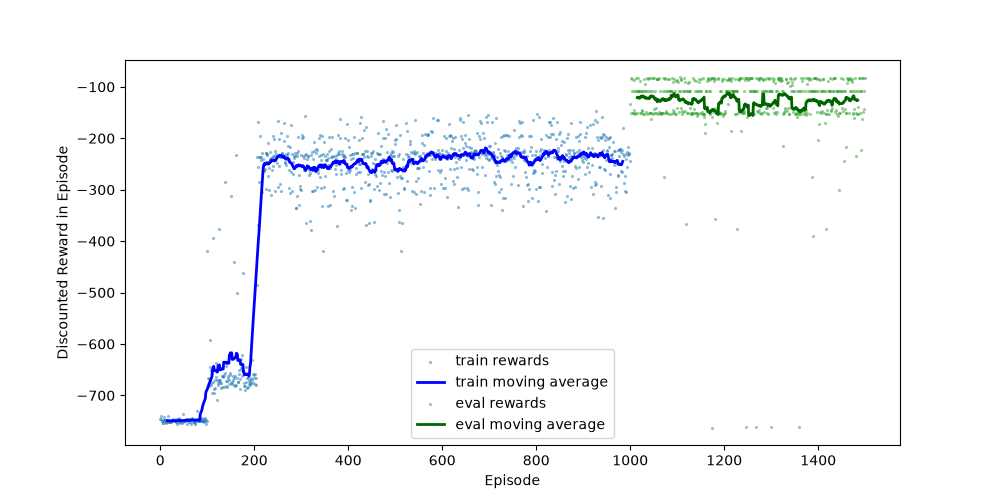

tabular


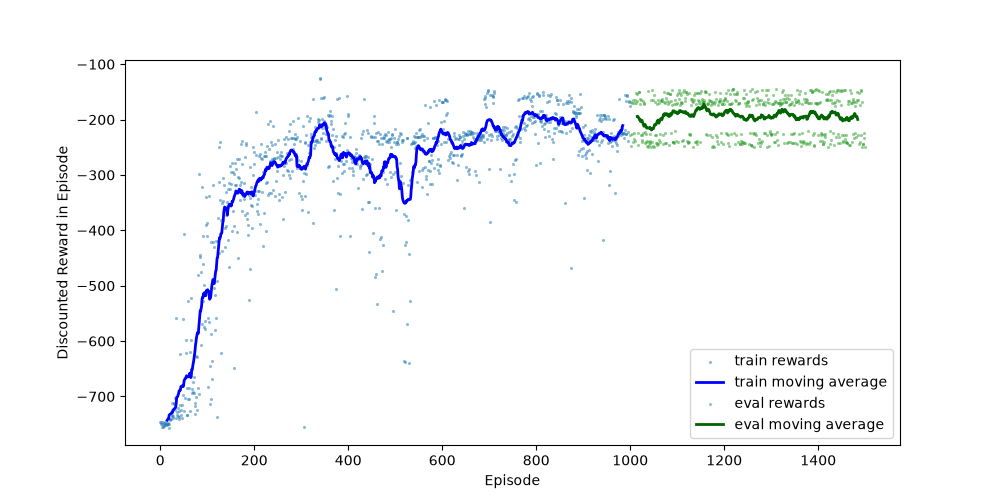

fapprox


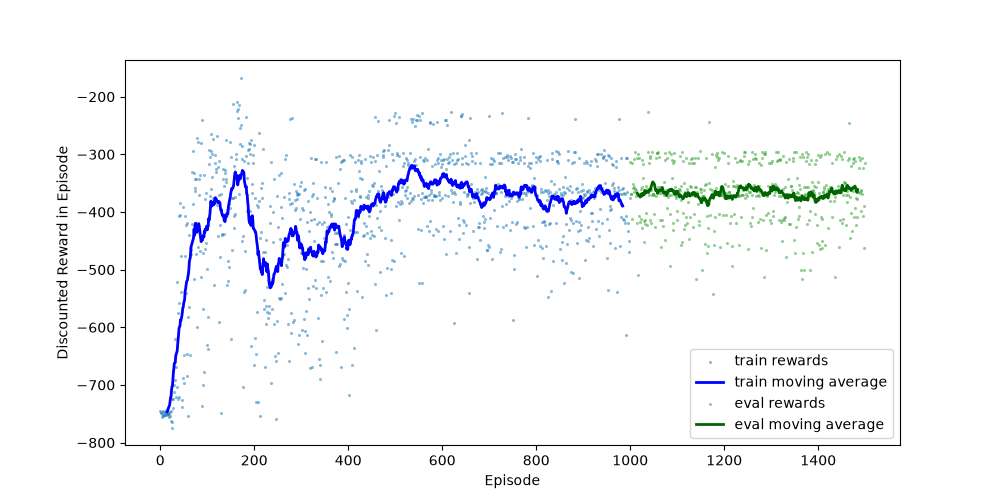

fapprox_maxspeed100000


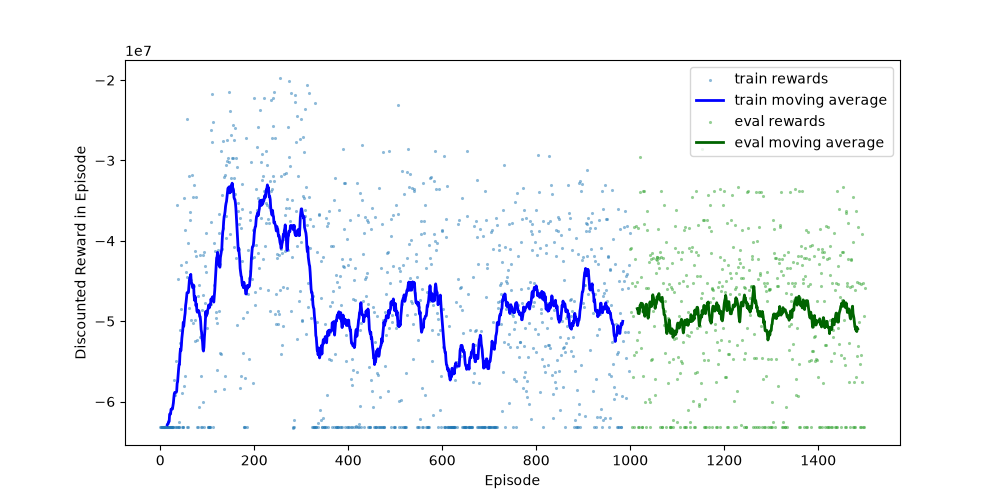

In [60]:
from IPython.display import Image, display
for prefix in ["mcvi", "tabular", "fapprox", "fapprox_maxspeed100000"]:
    print(prefix)
    display(Image(filename=str(ASSIGNMENTS[4].figures / f"{prefix}_1.png"), width=650))

### Assignment 4: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [61]:
run_grader(4)

========== START GRADING
----- START PART 3a-0-basic: Basic test of VI on problem 1.
Running value_iteration...
value_iteration: 20 iterations
----- END PART 3a-0-basic [took 0:00:00 (max allowed 5 seconds), 1/1 points]

----- START PART 3a-1-basic: Test on arbitrary n, reward and penalty.
Running value_iteration...
value_iteration: 113 iterations
----- END PART 3a-1-basic [took 0:00:00.005213 (max allowed 5 seconds), 2/2 points]

----- START PART 3a-2-hidden: Hidden test to make sure the code runs fast enough
Running value_iteration...
value_iteration: 1871 iterations
----- END PART 3a-2-hidden [took 0:00:02.627539 (max allowed 14 seconds), ???/2 points (hidden test ungraded)]

----- START PART 3b-0-basic: testing epsilon greedy for get_action.
----- END PART 3b-0-basic [took 0:00:00.006010 (max allowed 5 seconds), 2/2 points]

----- START PART 3b-1-basic: basic test of incorporate feedback.
Running value_iteration...
value_iteration: 2 iterations
----- END PART 3b-1-basic [took 0:00:

0

---
# Assignment 5: Pac-Man

Adversarial search for multi-agent Pac-Man: minimax with multiple min layers, alpha-beta pruning,
expectimax against random ghosts, and a custom evaluation function (extra credit).
Problems 1a, 3a, 4b, 5 are written (PDF §5). Standard library + tkinter only.
**Sanity values:** minimax root value on `minimaxClassic` = 9, 8, 7, −492 for depths 1–4;
on `mediumClassic` = 9, 18, 27, 36.

In [62]:
# Activate Assignment 5: imports and relative file paths now resolve inside its folder.
hw = use_assignment(5)
sub = load("submission")

Active: Assignment 5 - Pac-Man  (assignments\05_pacman)


## 5.1b — MinimaxAgent

**Task.** Depth-limited minimax. One depth = Pac-Man plus every ghost moving once.

**Approach.** A recursive `value(state, depth, agent)` implements the recurrence of PDF §5 (1a). End states return the score, depth 0 returns `self.evaluation_function`, Pac-Man takes the `max` and each ghost the `min`. Turns rotate through all agents, and the depth decreases only when play returns to Pac-Man, so one depth is Pac-Man plus every ghost. The root returns the action with the best successor value.

In [63]:
show_source(sub.MinimaxAgent)

class MinimaxAgent(MultiAgentSearchAgent):
    """
      Your minimax agent (problem 1)
    """

    def get_action(self, game_state: GameState) -> str:
        """
          Returns the minimax action from the current game_state using self.depth
          and self.evaluation_function. Terminal states can be found by one of the following:
          pacman won, pacman lost or there are no legal moves.

          Don't forget to limit the search depth using self.depth. Also, avoid modifying
          self.depth directly (e.g., when implementing depth-limited search) since it
          is a member variable that should stay fixed throughout runtime.

          Here are some method calls that might be useful when implementing minimax.

          game_state.get_legal_actions(agentIndex):
            Returns a list of legal actions for an agent
            agentIndex=0 means Pacman, ghosts are >= 1

          game_state.generate_successor(agentIndex, action):
            Returns the successor game state after an agent takes an action

          game_state.get_num_agents():
            Returns the total number of agents in the game

          game_state.get_score():
            Returns the score corresponding to the current state of the game

          game_state.is_win():
            Returns True if it's a winning state

          game_state.is_lose():
            Returns True if it's a losing state

          self.depth:
            The depth to which search should continue

          Hint: To implement minimax recursively, consider creating a helper function that
          takes the current game state, current depth, and current agent index as parameters.
        """

        # BEGIN_YOUR_CODE (our solution is 22 lines of code, but don't worry if you deviate from this)
        num_agents = game_state.get_num_agents()

        def successor_turn(agent: int, depth: int) -> Tuple[int, int]:
            """Whose turn is next, and the depth left: one unit of depth is Pac-Man plus every
            ghost moving once, so depth only decreases when play returns to Pac-Man."""
            next_agent = (agent + 1) % num_agents
            return next_agent, (depth - 1 if next_agent == self.index else depth)

        def value(state: GameState, depth: int, agent: int) -> float:
            """V_minmax(s, d): Pac-Man (agent 0) maximises, every ghost minimises."""
            actions = state.get_legal_actions(agent)
            if state.is_win() or state.is_lose() or not actions:
                return state.get_score()                      # Utility(s) at end states
            if depth == 0:
                return self.evaluation_function(state)        # Eval(s) at the depth limit
            next_agent, next_depth = successor_turn(agent, depth)
            child_values = [value(state.generate_successor(agent, action), next_depth, next_agent)
                            for action in actions]
            return max(child_values) if agent == self.index else min(child_values)

        # Root (a max node): choose Pac-Man's action whose successor has the highest value.
        next_agent, next_depth = successor_turn(self.index, self.depth)
        return max(game_state.get_legal_actions(self.index),
                   key=lambda action: value(game_state.generate_successor(self.index, action),
                                            next_depth, next_agent))
        # END_YOUR_CODE

In [64]:
run_grader(5, '1b-0-basic', '1b-1-basic', '1b-2-basic', '1b-3-basic')

========== START GRADING
----- START PART 1b-0-basic: Tests minimax for timeout on smallClassic.
('*** Running minimax (depth 2) on', 'smallClassic', '1 time(s).')
Pacman died! Score: -341
('Average Score:', -341.0)
('Scores:       ', '-341')
Win Rate:      0/1 (0.00)
('Record:       ', 'Loss')
('*** Finished running minimax (depth 2) on', 'smallClassic', 'after 0 seconds.')
*** Won 0 out of 1 games. Average score: -341.000000 ***
----- END PART 1b-0-basic [took 0:00:00.034575 (max allowed 10 seconds), 4/4 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [4/4 points + 0/0 extra credit]
========== START GRADING
----- START PART 1b-1-basic: Tests minimax for timeout on hidden test 1.
Running our grader (hidden from you)...
----- END PART 1b-1-basic [took 0:00:00.000999 (max al

========== START GRADING
----- START PART 1b-2-basic: Tests minimax for timeout on hidden test 2.
Running our grader (hidden from you)...
----- END PART 1b-2-basic [took 0:00:00.001001 (max allowed 10 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 points + 0/0 extra credit]
========== START GRADING
----- START PART 1b-3-basic: Tests minimax for timeout on hidden test 3.
Running our grader (hidden from you)...
----- END PART 1b-3-basic [took 0:00:00 (max allowed 10 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 points + 0/0

0

## 5.2a — AlphaBetaAgent

**Task.** Minimax with α-β pruning generalised to several min agents; must return the same values as minimax.

**Approach.** Same recursion with $(\alpha,\beta)$ bounds. A max node returns as soon as its value is at least $\beta$, and a ghost's min node as soon as its value is at most $\alpha$. Consecutive ghost layers are all min nodes, so they pass the same bounds down. The values equal minimax exactly; the cell below checks this against the handout's numbers.

In [65]:
show_source(sub.AlphaBetaAgent)

class AlphaBetaAgent(MultiAgentSearchAgent):
    """
      Your minimax agent with alpha-beta pruning (problem 2)
      You may reference the pseudocode for Alpha-Beta pruning here:
      en.wikipedia.org/wiki/Alpha%E2%80%93beta_pruning#Pseudocode
    """

    def get_action(self, game_state: GameState) -> str:
        """
          Returns the minimax action using self.depth and self.evaluation_function
        """

        # BEGIN_YOUR_CODE (our solution is 43 lines of code, but don't worry if you deviate from this)
        num_agents = game_state.get_num_agents()

        def successor_turn(agent: int, depth: int) -> Tuple[int, int]:
            next_agent = (agent + 1) % num_agents
            return next_agent, (depth - 1 if next_agent == self.index else depth)

        def value(state: GameState, depth: int, agent: int, alpha: float, beta: float) -> float:
            """Minimax value with alpha-beta pruning.

            alpha = best value Pac-Man (max) can already guarantee on the path to the root,
            beta  = best (lowest) value the ghosts (min) can already guarantee.
            With several ghosts, consecutive min layers share the same beta: each ghost's
            layer prunes as soon as its value drops to <= alpha, exactly like a single min node.
            """
            actions = state.get_legal_actions(agent)
            if state.is_win() or state.is_lose() or not actions:
                return state.get_score()
            if depth == 0:
                return self.evaluation_function(state)
            next_agent, next_depth = successor_turn(agent, depth)

            if agent == self.index:                      # max node
                best = float('-inf')
                for action in actions:
                    best = max(best, value(state.generate_successor(agent, action),
                                           next_depth, next_agent, alpha, beta))
                    if best >= beta:                     # a min ancestor will never allow this
                        return best
                    alpha = max(alpha, best)
                return best
            else:                                        # min node (one ghost)
                best = float('inf')
                for action in actions:
                    best = min(best, value(state.generate_successor(agent, action),
                                           next_depth, next_agent, alpha, beta))
                    if best <= alpha:                    # Pac-Man already has something better
                        return best
                    beta = min(beta, best)
                return best

        # Root (max node): evaluate children left to right, tightening alpha as we go.
        next_agent, next_depth = successor_turn(self.index, self.depth)
        alpha, best_action = float('-inf'), None
        for action in game_state.get_legal_actions(self.index):
            child_value = value(game_state.generate_successor(self.index, action),
                                next_depth, next_agent, alpha, float('inf'))
            if child_value > alpha or best_action is None:
                alpha, best_action = child_value, action
        return best_action
        # END_YOUR_CODE

In [66]:
run_grader(5, '2a-0-basic', '2a-1-basic', '2a-2-basic', '2a-3-basic')

========== START GRADING
----- START PART 2a-0-basic: Tests alphabeta for timeout on smallClassic.
('*** Running alphabeta (depth 2) on', 'smallClassic', '1 time(s).')
Pacman died! Score: 72
('Average Score:', 72.0)
('Scores:       ', '72')
Win Rate:      0/1 (0.00)
('Record:       ', 'Loss')
('*** Finished running alphabeta (depth 2) on', 'smallClassic', 'after 0 seconds.')
*** Won 0 out of 1 games. Average score: 72.000000 ***
----- END PART 2a-0-basic [took 0:00:00.044421 (max allowed 10 seconds), 4/4 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [4/4 points + 0/0 extra credit]
========== START GRADING
----- START PART 2a-1-basic: Tests alphabeta for timeout on hidden test 1.
Running our grader (hidden from you)...
----- END PART 2a-1-basic [took 0:00:00 (max allowed 1

========== START GRADING
----- START PART 2a-2-basic: Tests alphabeta for timeout on hidden test 2.
Running our grader (hidden from you)...
----- END PART 2a-2-basic [took 0:00:00.001504 (max allowed 10 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 points + 0/0 extra credit]
========== START GRADING
----- START PART 2a-3-basic: Tests alphabeta for timeout on hidden test 3.
Running our grader (hidden from you)...
----- END PART 2a-3-basic [took 0:00:00.000586 (max allowed 10 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 p

0

## 5.3b — ExpectimaxAgent

**Task.** Ghost layers average uniformly over their legal actions.

**Approach.** Identical to minimax except that a ghost node returns the **mean** of its children's values, which models a ghost that picks each legal action with probability $1/|\text{Actions}(s)|$.

In [67]:
show_source(sub.ExpectimaxAgent)

class ExpectimaxAgent(MultiAgentSearchAgent):
    """
      Your expectimax agent (problem 3)
    """

    def get_action(self, game_state: GameState) -> str:
     """
       Returns the expectimax action using self.depth and self.evaluation_function

       All ghosts should be modeled as choosing uniformly at random from their
       legal moves.
     """

     # BEGIN_YOUR_CODE (our solution is 20 lines of code, but don't worry if you deviate from this)
     num_agents = game_state.get_num_agents()

     def successor_turn(agent: int, depth: int) -> Tuple[int, int]:
         next_agent = (agent + 1) % num_agents
         return next_agent, (depth - 1 if next_agent == self.index else depth)

     def value(state: GameState, depth: int, agent: int) -> float:
         """V_exptmax(s, d): Pac-Man maximises; each ghost picks a legal move uniformly at
         random, so a ghost node's value is the *average* of its children's values."""
         actions = state.get_legal_actions(agent)
         if state.is_win() or state.is_lose() or not actions:
             return state.get_score()
         if depth == 0:
             return self.evaluation_function(state)
         next_agent, next_depth = successor_turn(agent, depth)
         child_values = [value(state.generate_successor(agent, action), next_depth, next_agent)
                         for action in actions]
         if agent == self.index:
             return max(child_values)
         return sum(child_values) / len(child_values)

     next_agent, next_depth = successor_turn(self.index, self.depth)
     return max(game_state.get_legal_actions(self.index),
                key=lambda action: value(game_state.generate_successor(self.index, action),
                                         next_depth, next_agent))
     # END_YOUR_CODE

In [68]:
run_grader(5, '3b-0-basic', '3b-1-basic', '3b-2-basic', '3b-3-basic')

========== START GRADING
----- START PART 3b-0-basic: Tests expectimax for timeout on smallClassic.
('*** Running expectimax (depth 2) on', 'smallClassic', '1 time(s).')
Pacman died! Score: -317
('Average Score:', -317.0)
('Scores:       ', '-317')
Win Rate:      0/1 (0.00)
('Record:       ', 'Loss')
('*** Finished running expectimax (depth 2) on', 'smallClassic', 'after 0 seconds.')
*** Won 0 out of 1 games. Average score: -317.000000 ***
----- END PART 3b-0-basic [took 0:00:00.016641 (max allowed 10 seconds), 4/4 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [4/4 points + 0/0 extra credit]
========== START GRADING
----- START PART 3b-1-basic: Tests expectimax for timeout on hidden test 1.
Running our grader (hidden from you)...
----- END PART 3b-1-basic [took 0:00:00.00

========== START GRADING
----- START PART 3b-2-basic: Tests expectimax for timeout on hidden test 2.
Running our grader (hidden from you)...
----- END PART 3b-2-basic [took 0:00:00 (max allowed 10 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 points + 0/0 extra credit]
========== START GRADING
----- START PART 3b-3-basic: Tests expectimax for timeout on hidden test 3.
Running our grader (hidden from you)...
----- END PART 3b-3-basic [took 0:00:00 (max allowed 10 seconds), 0/0 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [0/0 points + 0/0 

0

## 5.4a — better_evaluation_function (extra credit)

**Task.** State evaluation function; target is winning > 50 % on `smallClassic` at depth 2 with a high average score.

**Approach.** Game score plus progress terms that a depth-2 search can see. One BFS gives maze distances. We add $+10/(1+d_{\text{food}})$, $-4$ per remaining pellet and $-20$ per remaining capsule; $+200/(1+d)$ for each scared ghost reachable before its timer runs out; $-500$ for an adjacent active ghost, otherwise a weak $-2/d$. The experiment cell below reproduces the disabled extra-credit grader and an ablation of these terms.

In [69]:
show_source(sub.better_evaluation_function)

def better_evaluation_function(current_game_state: GameState) -> float:
    """
      Your extreme, unstoppable evaluation function (problem 4). Note that you can't fix a seed in this function.
    """

    # BEGIN_YOUR_CODE (our solution is 16 lines of code, but don't worry if you deviate from this)
    # Start from the game score (it already rewards eating food, ghosts and winning) and add
    # terms that make *progress* visible to a depth-2 search, which otherwise sees no
    # difference between most moves:
    #   - true maze distance to the nearest food (reciprocal, so being close matters most),
    #   - remaining food and capsules (fewer is better),
    #   - scared ghosts within reach are worth chasing (+200 points each when eaten),
    #   - active ghosts are dangerous only when they are adjacent.
    if current_game_state.is_win() or current_game_state.is_lose():
        return current_game_state.get_score()

    pacman_pos = current_game_state.get_pacman_position()
    walls = current_game_state.get_walls()
    food = current_game_state.get_food()

    # Breadth-first search from Pac-Man gives real maze distances (walls included).
    dist = {pacman_pos: 0}
    frontier = [pacman_pos]
    while frontier:
        next_frontier = []
        for (x, y) in frontier:
            for nx, ny in ((x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)):
                if not walls[nx][ny] and (nx, ny) not in dist:
                    dist[(nx, ny)] = dist[(x, y)] + 1
                    next_frontier.append((nx, ny))
        frontier = next_frontier

    def maze_distance(pos) -> int:
        return dist.get((int(pos[0]), int(pos[1])), 1000)

    food_list = food.as_list()
    nearest_food = min(maze_distance(f) for f in food_list) if food_list else 0
    capsules = current_game_state.get_capsules()

    value = current_game_state.get_score()
    value += 10.0 / (nearest_food + 1)
    value -= 4.0 * len(food_list)
    value -= 20.0 * len(capsules)

    for ghost in current_game_state.get_ghost_states():
        d = maze_distance(ghost.get_position())
        if ghost.scaredTimer > d:          # reachable before it recovers: hunt it
            value += 200.0 / (d + 1)
        elif d <= 1:                       # an active ghost next to us: very bad
            value -= 500.0
        else:
            value -= 2.0 / d
    return value
    # END_YOUR_CODE

## 5.checks — Handout values and Problem 5 (trappedClassic)

1. An independent plain minimax confirms the handout's root values (minimaxClassic 9, 8, 7, −492;
   mediumClassic 9, 18, 27), and we assert that `MinimaxAgent` and `AlphaBetaAgent` pick an action attaining them.
2. Minimax vs expectimax on `trappedClassic` (depth 3, 50 seeded games each), used in PDF §5 (5a).

In [70]:
run_script(5, str(REPO_ROOT / "scripts" / "pacman_experiments.py"))

1) Root minimax values vs. the handout
   minimaxClassic  depth 1: root value     9 (handout     9) | MinimaxAgent   -> West  (0.00s) | AlphaBetaAgent -> West  (0.00s)
   minimaxClassic  depth 2: root value     8 (handout     8) | MinimaxAgent   -> East  (0.00s) | AlphaBetaAgent -> East  (0.00s)
   minimaxClassic  depth 3: root value     7 (handout     7) | MinimaxAgent   -> East  (0.00s) | AlphaBetaAgent -> East  (0.00s)
   minimaxClassic  depth 4: root value  -492 (handout  -492) | MinimaxAgent   -> West  (0.01s) | AlphaBetaAgent -> West  (0.00s)
   mediumClassic   depth 1: root value     9 (handout     9) | MinimaxAgent   -> East  (0.00s) | AlphaBetaAgent -> East  (0.00s)
   mediumClassic   depth 2: root value    18 (handout    18) | MinimaxAgent   -> East  (0.00s) | AlphaBetaAgent -> East  (0.00s)
   mediumClassic   depth 3: root value    27 (handout    27) | MinimaxAgent   -> East  (0.00s) | AlphaBetaAgent -> East  (0.00s)
   OK: both agents choose actions attaining the handout's 

0

## 5.4b — Extra credit: grader-style run and ablation

The extra-credit grader part (`4a-1-basic`) is commented out in the provided `grader.py`, so we reproduce
it: depth-2 expectimax, `smallClassic`, two random ghosts, 20 games, seed `'testing'`. Full credit needs
more than half the games won and an average winning score of at least 1600. The same script also evaluates
variants that each remove one idea from the evaluation function (discussed in PDF §5, 4b). Runtime about 40 s.

In [71]:
run_script(5, str(REPO_ROOT / "scripts" / "pacman_eval_ablation.py"))

variant                                                           wins  avg win score  avg score
submitted (BFS distances, hunt scared ghosts, danger radius 1)    15/20         1663.7     1274.0
Manhattan instead of maze (BFS) distances                         19/20         1630.1     1577.2
no scared-ghost hunting term                                      19/20         1349.9     1266.8
danger radius 3 instead of 1 (more cautious)                      15/20         1598.0     1277.8
game score only (score_evaluation_function)                        2/20          962.0     -398.8


0

### Assignment 5: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [72]:
run_grader(5)

========== START GRADING
----- START PART 1b-0-basic: Tests minimax for timeout on smallClassic.
('*** Running minimax (depth 2) on', 'smallClassic', '1 time(s).')
Pacman died! Score: -377
('Average Score:', -377.0)
('Scores:       ', '-377')
Win Rate:      0/1 (0.00)
('Record:       ', 'Loss')
('*** Finished running minimax (depth 2) on', 'smallClassic', 'after 0 seconds.')
*** Won 0 out of 1 games. Average score: -377.000000 ***
----- END PART 1b-0-basic [took 0:00:00.012458 (max allowed 10 seconds), 4/4 points]

----- START PART 1b-1-basic: Tests minimax for timeout on hidden test 1.
Running our grader (hidden from you)...
----- END PART 1b-1-basic [took 0:00:00 (max allowed 10 seconds), 0/0 points]

----- START PART 1b-2-basic: Tests minimax for timeout on hidden test 2.
----- END PART 1b-2-basic [took 0:00:00 (max allowed 10 seconds), 0/0 points]

----- START PART 1b-3-basic: Tests minimax for timeout on hidden test 3.
----- END PART 1b-3-basic [took 0:00:00 (max allowed 10 second

0

---
# Assignment 6: Bayesian Networks (Car Tracking)

HMM-style exact inference to track other cars from noisy microphone distances: an emission update
(`observe`), a transition update (`elapseTime`), and a sensor-deception variant.
Problems 1a-b, 2a-b, 3, 4a, 4c-f are written (PDF §6). Always call `util.pdf(mean, std, value)`
positionally, as the handout requires.

In [73]:
# Activate Assignment 6: imports and relative file paths now resolve inside its folder.
hw = use_assignment(6)
sub = load("submission")

Active: Assignment 6 - Bayesian Networks (Car Tracking)  (assignments\06_bayesian)


## 6.1c — ExactInference.observe

**Task.** Multiply each tile's belief by p(d_t | c) = N(d_t; ‖a_t − c‖, σ²) and normalise.

**Approach.** Bayes' rule over all tiles: multiply each tile's belief by the Gaussian emission density `util.pdf(true_dist, SONAR_STD, observedDist)` (argument order *mean, std, value*), then normalise. `util.pdf` is looked up at call time, as the grader requires.

In [74]:
show_source(sub.ExactInference.observe)

def observe(self, agentX: int, agentY: int, observedDist: float) -> None:
        # BEGIN_YOUR_CODE (our solution is 7 lines of code, but don't worry if you deviate from this)
        # Bayes' rule for a hidden location C and observed distance D_t = d_t:
        #   P(C = c | d_1..d_t)  ∝  P(C = c | d_1..d_{t-1}) * p(d_t | c),
        # where the emission p(d_t | c) is a Gaussian density centred on the true distance
        # between our car (agentX, agentY) and the centre of tile c, with std Const.SONAR_STD.
        for row in range(self.belief.getNumRows()):
            for col in range(self.belief.getNumCols()):
                true_dist = math.hypot(agentX - util.colToX(col), agentY - util.rowToY(row))
                emission = util.pdf(true_dist, Const.SONAR_STD, observedDist)  # pdf(mean, std, value)
                self.belief.setProb(row, col, self.belief.getProb(row, col) * emission)
        self.belief.normalize()
        # END_YOUR_CODE

In [75]:
run_grader(6, '1c-0-basic', '1c-1-basic')

========== START GRADING
----- START PART 1c-0-basic: 1c basic test for emission probabilities
----- END PART 1c-0-basic [took 0:00:00.005523 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]
========== START GRADING
----- START PART 1c-1-basic: 1c test ordering of pdf
----- END PART 1c-1-basic [took 0:00:00.004535 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


0

## 6.2c — ExactInference.elapseTime

**Task.** Forward step: belief'(c') ∝ Σ_c belief(c) · transProb[(c, c')], then normalise.

**Approach.** Forward step of the HMM: start a fresh all-zero belief, and for every `((old, new), p)` in the sparse transition table add `belief[old] * p` to `new`, then normalise. Only the old belief is read, and the cost is proportional to the number of transitions.

In [76]:
show_source(sub.ExactInference.elapseTime)

def elapseTime(self) -> None:
        if self.skipElapse: ### ONLY FOR THE GRADER TO USE IN Problem 1
            return
        # BEGIN_YOUR_CODE (our solution is 7 lines of code, but don't worry if you deviate from this)
        # Forward step of the HMM:
        #   P(C_{t+1} = c' | d_1..d_t) ∝ sum_c P(C_t = c | d_1..d_t) * p(c' | c).
        # Build the new belief in a separate grid (all zeros) so that every term uses only the
        # *current* belief, then iterate over the sparse transition table (pairs not listed
        # have probability 0).
        new_belief = util.Belief(self.belief.getNumRows(), self.belief.getNumCols(), 0.0)
        for (old_tile, new_tile), trans_prob in self.transProb.items():
            new_belief.addProb(new_tile[0], new_tile[1],
                               self.belief.getProb(old_tile[0], old_tile[1]) * trans_prob)
        new_belief.normalize()
        self.belief = new_belief
        # END_YOUR_CODE

In [77]:
run_grader(6, '2c-0-basic')

========== START GRADING
----- START PART 2c-0-basic: test correctness of elapseTime()
----- END PART 2c-0-basic [took 0:00:00.003509 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


0

## 6.4b — ExactInferenceWithSensorDeception.observe

**Task.** Apply the skew transform D' = D/(1+s²) + √(2/(1+s²)) before the usual emission update.

**Approach.** Transform the reading $D'=D/(1+s^2)+\sqrt{2/(1+s^2)}$ and reuse the parent's `observe`. With $s=0.5$ the tracker believes cars are closer (80 % of the distance + 1.26).

In [78]:
show_source(sub.ExactInferenceWithSensorDeception.observe)

def observe(self, agentX: int, agentY: int, observedDist: float) -> None:
        # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
        # The attacker skews every reading: D'_t = D_t / (1 + s^2) + sqrt(2 / (1 + s^2)).
        # Apply that transformation, then run the ordinary emission update on the skewed value.
        shrink = 1.0 / (1.0 + self.skewness ** 2)
        skewed_dist = shrink * observedDist + math.sqrt(2.0 * shrink)
        super().observe(agentX, agentY, skewed_dist)
        # END_YOUR_CODE

In [79]:
run_grader(6, '4b-0-basic')

========== START GRADING
----- START PART 4b-0-basic: 4b basic test for sensor deception
----- END PART 4b-0-basic [took 0:00:00.004092 (max allowed 5 seconds), 3/3 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [3/3 points + 0/0 extra credit]


0

## 6.4d — Exact inference vs particle filtering (Problem 4d)

`drive.py` shows this comparison in a Tk window. `scripts/car_tracking_comparison.py` measures it headlessly
on the Lombard map: a simulated car moves with the learned transition model, our car is parked mid-map, and
both trackers receive the same noisy readings (20 runs × 40 steps). The table reports the distance from the most
likely tile to the true car, the expected distance under the belief, how many tiles carry more than 1 % of the
probability, and the time per step.

In [80]:
run_script(6, str(REPO_ROOT / "scripts" / "car_tracking_comparison.py"))

Lombard map: 23 x 11 = 253 tiles, 20 runs x 40 steps, 200 particles, sonar std 20.0
tracker     MAP-tile error  expected error  tiles >1%  ms/step
exact                 65.0            84.1        9.7     1.83
particle              78.9            92.5        7.9     3.79
(errors in map units; one tile is 30 units wide)


0

## 6.drive — Interactive visualisation (optional, opens a Tk window)

Not graded and not run automatically. Uncomment a line to watch the trackers drive.

In [81]:
# run_script(6, "drive.py", "-a", "-p", "-d", "-k", "1", "-i", "exactInference")
# run_script(6, "drive.py", "-a", "-d", "-k", "3", "-i", "particleFilter")

### Assignment 6: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [82]:
run_grader(6)

========== START GRADING
----- START PART 1c-0-basic: 1c basic test for emission probabilities
----- END PART 1c-0-basic [took 0:00:00.005068 (max allowed 5 seconds), 2/2 points]

----- START PART 1c-1-basic: 1c test ordering of pdf
----- END PART 1c-1-basic [took 0:00:00.002926 (max allowed 5 seconds), 2/2 points]

----- START PART 1c-2-hidden: 1c advanced test for emission probabilities
----- END PART 1c-2-hidden [took 0:00:00.004005 (max allowed 5 seconds), ???/3 points (hidden test ungraded)]

----- START PART 2c-0-basic: test correctness of elapseTime()
----- END PART 2c-0-basic [took 0:00:00.003997 (max allowed 5 seconds), 2/2 points]

----- START PART 2c-1i-hidden: advanced test for transition probabilities, strict time limit
----- END PART 2c-1i-hidden [took 0:00:00.027019 (max allowed 5 seconds), ???/2 points (hidden test ungraded)]

----- START PART 2c-1ii-hidden: 2c test for transition probabilities on other maps, loose time limit
----- END PART 2c-1ii-hidden [took 0:00:00.0

0

---
# Assignment 7: From Language to Logic

Translate English into propositional / first-order logic formulas (`logic.py`), solve a liar puzzle,
encode a theorem about odd/even integers, and (extra credit) write semantic-parsing grammar rules.
Problems 6 and 7 are written (PDF §7). **All tests are visible**: passing every local test means full credit.

In [83]:
# Activate Assignment 7: imports and relative file paths now resolve inside its folder.
hw = use_assignment(7)
sub = load("submission")

Active: Assignment 7 - From Language to Logic  (assignments\07_logic)


## 7.1 — Propositional logic (1a–1c)

**Task.** Summer ∧ California → ¬Rain; Wet ↔ (Rain ∨ Sprinklers); Day ⊕ Night.

**Approach.** Direct translations with `Implies`, `Equiv` and `Xor` (the latter is $(A\vee B)\wedge\neg(A\wedge B)$).

In [84]:
show_source(sub.formula1a, sub.formula1b, sub.formula1c)

def formula1a() -> Formula:
    # Predicates to use:
    Summer = Atom('Summer')               # whether it's summer
    California = Atom('California')       # whether we're in California
    Rain = Atom('Rain')                   # whether it's raining
    # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
    # (Summer ∧ California) → ¬Rain
    return Implies(And(Summer, California), Not(Rain))
    # END_YOUR_CODE

def formula1b() -> Formula:
    # Predicates to use:
    Rain = Atom('Rain')              # whether it is raining
    Wet = Atom('Wet')                # whether it it wet
    Sprinklers = Atom('Sprinklers')  # whether the sprinklers are on
    # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
    # Wet ↔ (Rain ∨ Sprinklers)
    return Equiv(Wet, Or(Rain, Sprinklers))
    # END_YOUR_CODE

def formula1c() -> Formula:
    # Predicates to use:
    Day = Atom('Day')     # whether it's day
    Night = Atom('Night') # whether it's night
    # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
    # Exclusive or: (Day ∨ Night) ∧ ¬(Day ∧ Night)
    return Xor(Day, Night)
    # END_YOUR_CODE

In [85]:
run_grader(7, '1a', '1b', '1c')

========== START GRADING
----- START PART 1a: Test formula 1a implementation
You matched the 7 models
Example model: {'Summer'}
----- END PART 1a [took 0:00:00.001000 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]
========== START GRADING
----- START PART 1b: Test formula 1b implementation
You matched the 4 models
Example model: {'Wet', 'Sprinklers'}
----- END PART 1b [took 0:00:00.001001 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


========== START GRADING
----- START PART 1c: Test formula 1c implementation
You matched the 2 models
Example model: {'Night'}
----- END PART 1c [took 0:00:00.000997 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


0

## 7.2 — First-order logic (2a–2d)

**Task.** Parents, childless persons, Father and Granddaughter definitions.

**Approach.** Quantified formulas; the definitions of Father and Granddaughter are biconditionals (∀x∀y. Defined ↔ body), so they also rule out unintended instances.

In [86]:
show_source(sub.formula2a, sub.formula2b, sub.formula2c, sub.formula2d)

def formula2a() -> Formula:
    # Predicates to use:
    def Person(x): return Atom('Person', x)        # whether x is a person
    def Parent(x, y): return Atom('Parent', x, y)  # whether x's parent is y

    # Note: You do NOT have to enforce that the parent is a "person"
    # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
    # ∀x. Person(x) → ∃y. Parent(x, y)
    return Forall('$x', Implies(Person('$x'), Exists('$y', Parent('$x', '$y'))))
    # END_YOUR_CODE

def formula2b() -> Formula:
    # Predicates to use:
    def Person(x): return Atom('Person', x)        # whether x is a person
    def Child(x, y): return Atom('Child', x, y)    # whether x has a child y

    # Note: You do NOT have to enforce that the child is a "person"
    # BEGIN_YOUR_CODE (our solution is 1 line of code, but don't worry if you deviate from this)
    # ∃x. Person(x) ∧ ¬∃y. Child(x, y)
    return Exists('$x', And(Person('$x'), Not(Exists('$y', Child('$x', '$y')))))
    # END_YOUR_CODE

def formula2c() -> Formula:
    # Predicates to use:
    def Male(x): return Atom('Male', x)                  # whether x is male
    def Parent(x, y): return Atom('Parent', x, y)        # whether x has a parent y
    def Father(x, y): return Atom('Father', x, y)        # whether x has a father y
    # BEGIN_YOUR_CODE (our solution is 4 lines of code, but don't worry if you deviate from this)
    # y is x's father exactly when y is a male parent of x:
    # ∀x ∀y. Father(x, y) ↔ (Male(y) ∧ Parent(x, y))
    return Forall('$x', Forall('$y', Equiv(Father('$x', '$y'),
                                           And(Male('$y'), Parent('$x', '$y')))))
    # END_YOUR_CODE

def formula2d() -> Formula:
    # Predicates to use:
    def Female(x): return Atom('Female', x)                      # whether x is female
    def Child(x, y): return Atom('Child', x, y)                  # whether x has a child y
    def Granddaughter(x, y): return Atom('Granddaughter', x, y)  # whether x has a granddaughter y
    # BEGIN_YOUR_CODE (our solution is 5 lines of code, but don't worry if you deviate from this)
    # y is x's granddaughter exactly when y is female and a child of one of x's children:
    # ∀x ∀y. Granddaughter(x, y) ↔ (Female(y) ∧ ∃z. Child(x, z) ∧ Child(z, y))
    return Forall('$x', Forall('$y', Equiv(
        Granddaughter('$x', '$y'),
        And(Female('$y'), Exists('$z', And(Child('$x', '$z'), Child('$z', '$y')))))))
    # END_YOUR_CODE

In [87]:
run_grader(7, '2a', '2b', '2c', '2d')

========== START GRADING
----- START PART 2a: Test formula 2a implementation
You matched the 343 models
Example model: {'Person(o2)', 'Parent(o3,o1)', 'Parent(o2,o3)'}
----- END PART 2a [took 0:00:00.004096 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]
========== START GRADING
----- START PART 2b: Test formula 2b implementation
You matched the 169 models
Example model: {'Child(o3,o1)', 'Child(o3,o2)', 'Person(o2)', 'Child(o1,o2)'}
----- END PART 2b [took 0:00:00.002800 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grade

========== START GRADING
----- START PART 2c: Test formula 2c implementation
You matched the 4096 models
Example model: {'Parent(o2,o1)', 'Father(o1,o2)', 'Parent(o3,o3)', 'Father(o3,o3)', 'Parent(o1,o2)', 'Male(o3)', 'Father(o2,o3)', 'Parent(o2,o3)', 'Male(o2)'}
----- END PART 2c [took 0:00:00.181780 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


========== START GRADING
----- START PART 2d: Test formula 2d implementation
You matched the 4096 models
Example model: {'Child(o3,o3)', 'Child(o1,o3)', 'Female(o3)', 'Child(o2,o3)', 'Child(o3,o1)', 'Child(o1,o2)', 'Child(o2,o1)', 'Granddaughter(o3,o3)', 'Granddaughter(o2,o3)', 'Granddaughter(o1,o3)'}
----- END PART 2d [took 0:00:00.283793 (max allowed 5 seconds), 2/2 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [2/2 points + 0/0 extra credit]


0

## 7.3a — Liar puzzle

**Task.** Six formulas: four testimonies, exactly one truth-teller, exactly one culprit.

**Approach.** Each testimony is `Equiv(TellTruth(speaker), statement)`. "Exactly one" is $\exists x.\,P(x)\wedge\forall y.\,(P(y)\to x=y)$, used for both the truth-teller and the culprit. `3a-run` asks the knowledge base who crashed the server: **Mark**.

In [88]:
show_source(sub.liar)

def liar() -> Tuple[List[Formula], Formula]:
    def TellTruth(x): return Atom('TellTruth', x)
    def CrashedServer(x): return Atom('CrashedServer', x)
    mark = Constant('mark')
    john = Constant('john')
    nicole = Constant('nicole')
    susan = Constant('susan')
    formulas = []
    # We provide the formula for fact 0 here.
    formulas.append(Equiv(TellTruth(mark), Not(CrashedServer(mark))))
    # You should add 5 formulas, one for each of facts 1-5.
    # BEGIN_YOUR_CODE (our solution is 11 lines of code, but don't worry if you deviate from this)
    # Each testimony is true exactly when the speaker tells the truth.
    # 1. John: "It was Nicole!"
    formulas.append(Equiv(TellTruth(john), CrashedServer(nicole)))
    # 2. Nicole: "It wasn't me, it was Susan!"
    formulas.append(Equiv(TellTruth(nicole), And(Not(CrashedServer(nicole)), CrashedServer(susan))))
    # 3. Susan: "Nicole's a liar."
    formulas.append(Equiv(TellTruth(susan), Not(TellTruth(nicole))))
    # 4. Exactly one truth-teller: someone tells the truth, and anyone who does is that person.
    formulas.append(Exists('$x', And(TellTruth('$x'),
                                     Forall('$y', Implies(TellTruth('$y'), Equals('$x', '$y'))))))
    # 5. Exactly one person crashed the server (same "exactly one" pattern).
    formulas.append(Exists('$x', And(CrashedServer('$x'),
                                     Forall('$y', Implies(CrashedServer('$y'), Equals('$x', '$y'))))))
    # END_YOUR_CODE
    query = CrashedServer('$x')
    return (formulas, query)

In [89]:
run_grader(7, '3a-0', '3a-1', '3a-2', '3a-3', '3a-4', '3a-5', '3a-all', '3a-run')

========== START GRADING
----- START PART 3a-0: test implementation of statement 0 for 3a
----- END PART 3a-0 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]
========== START GRADING
----- START PART 3a-1: test implementation of statement 1 for 3a
----- END PART 3a-1 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-2: test implementation of statement 2 for 3a
----- END PART 3a-2 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-3: test implementation of statement 3 for 3a
----- END PART 3a-3 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-4: test implementation of statement 4 for 3a
----- END PART 3a-4 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-5: test implementation of statement 5 for 3a
----- END PART 3a-5 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-all: test implementation of all for 3a
You matched the 1 models
Example model: {'TellTruth(susan)', 'CrashedServer(mark)'}
----- END PART 3a-all [took 0:00:00.001996 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 3a-run: test implementation of run for 3a
>>>>> I learned something.
Query: TELL[And(Implies(TellTruth(mark),Not(CrashedServer(mark))),Implies(Not(CrashedServer(mark)),TellTruth(mark))), standardized: ['And(Implies(TellTruth(mark),Not(CrashedServer(mark))),Implies(Not(CrashedServer(mark)),TellTruth(mark)))']]
An example of a model where query is TRUE:
('*', 'Object(john)', '=', 'True')
('*', 'Object(mark)', '=', 'True')
('*', 'Object(nicole)', '=', 'True')
('*', 'Object(susan)', '=', 'True')
('*', 'TellTruth(mark)', '=', 'True')
('*', '(other atoms if any)', '=', 'False')
An example of a model where query is FALSE:
('*', 'Object(john)', '=', 'True')
('*', 'Object(mark)', '=', 'True')
('*', 'Object(nicole)', '=', 'True')
('*', 'Object(susan)', '=', 'True')
('*', '(other atoms if any)', '=', 'False')
>>>>> I learned something.
Query: TELL[And(Implies(TellTruth(john),CrashedServer(nicole)),Implies(CrashedServer(nicole),TellTruth(john))), standardi

0

## 7.4a — Odd and even integers

**Task.** Six axioms; the query (an even number larger than every x) is checked by model checking.

**Approach.** Six axioms (unique successor, even XOR odd, parity alternates, successor is larger, Larger is transitive). `4a-run` proves by model checking that every number has a larger even number.

In [90]:
show_source(sub.ints)

def ints() -> Tuple[List[Formula], Formula]:
    def Even(x): return Atom('Even', x)                  # whether x is even
    def Odd(x): return Atom('Odd', x)                    # whether x is odd
    def Successor(x, y): return Atom('Successor', x, y)  # whether x's successor is y
    def Larger(x, y): return Atom('Larger', x, y)        # whether x is larger than y
    # Note: all objects are numbers, so we don't need to define Number as an
    # explicit predicate.
    # Note: pay attention to the order of arguments of Successor and Larger.
    # Populate |formulas| with the 6 laws above and set |query| to be the
    # query.
    # Hint: You might want to use the Equals predicate, defined in logic.py.  This
    # predicate is used to assert that two objects are the same.
    formulas = []
    query = None
    # BEGIN_YOUR_CODE (our solution is 23 lines of code, but don't worry if you deviate from this)
    # 0. Every x has exactly one successor y, and y ≠ x:
    #    ∀x ∃y. Successor(x, y) ∧ ¬Equals(x, y) ∧ ∀z. (Successor(x, z) → Equals(y, z))
    formulas.append(Forall('$x', Exists('$y', AndList([
        Successor('$x', '$y'),
        Not(Equals('$x', '$y')),
        Forall('$z', Implies(Successor('$x', '$z'), Equals('$y', '$z'))),
    ]))))
    # 1. Every number is even or odd, but not both.
    formulas.append(Forall('$x', Xor(Even('$x'), Odd('$x'))))
    # 2. The successor of an even number is odd.
    formulas.append(Forall('$x', Forall('$y', Implies(And(Even('$x'), Successor('$x', '$y')),
                                                      Odd('$y')))))
    # 3. The successor of an odd number is even.
    formulas.append(Forall('$x', Forall('$y', Implies(And(Odd('$x'), Successor('$x', '$y')),
                                                      Even('$y')))))
    # 4. The successor of x is larger than x  (Larger(a, b) means "a is larger than b").
    formulas.append(Forall('$x', Forall('$y', Implies(Successor('$x', '$y'), Larger('$y', '$x')))))
    # 5. Larger is transitive.
    formulas.append(Forall('$x', Forall('$y', Forall('$z', Implies(
        And(Larger('$x', '$y'), Larger('$y', '$z')), Larger('$x', '$z'))))))
    # END_YOUR_CODE
    query = Forall('$x', Exists('$y', And(Even('$y'), Larger('$y', '$x'))))
    return (formulas, query)

In [91]:
run_grader(7, '4a-0', '4a-1', '4a-2', '4a-3', '4a-4', '4a-5', '4a-all', '4a-run')

========== START GRADING
----- START PART 4a-0: test implementation of statement 0 for 4a
----- END PART 4a-0 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-1: test implementation of statement 1 for 4a
----- END PART 4a-1 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-2: test implementation of statement 2 for 4a
----- END PART 4a-2 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-3: test implementation of statement 3 for 4a
----- END PART 4a-3 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-4: test implementation of statement 4 for 4a
----- END PART 4a-4 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-5: test implementation of statement 5 for 4a
----- END PART 4a-5 [took 0:00:00 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-all: test implementation of all for 4a
You matched the 36 models
Example model: {'Larger(o1,o1)', 'Odd(o2)', 'Successor(o1,o2)', 'Larger(o3,o3)', 'Larger(o2,o2)', 'Even(o1)', 'Successor(o2,o1)', 'Successor(o3,o1)', 'Larger(o1,o3)', 'Larger(o2,o1)', 'Odd(o3)', 'Larger(o2,o3)', 'Larger(o1,o2)'}
----- END PART 4a-all [took 0:00:00.143318 (max allowed 10000 seconds), 1/1 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to verify that the functions do not crash and run within the time limit.
Points for these parts not assigned by the grader (indicated by "--").
========== END GRADING [1/1 points + 0/0 extra credit]


========== START GRADING
----- START PART 4a-run: test implementation of run for 4a
>>>>> I learned something.
Query: TELL[Forall($x,Exists($y,And(And(Successor($x,$y),Not(Equals($x,$y))),Forall($z,Implies(Successor($x,$z),Equals($y,$z)))))), standardized: ['Forall($x,Exists($y,And(And(Successor($x,$y),Not(Equals($x,$y))),Forall($z,Implies(Successor($x,$z),Equals($y,$z))))))']]
An example of a model where query is TRUE:
('*', 'Object(o1)', '=', 'True')
('*', 'Object(o2)', '=', 'True')
('*', 'Object(o3)', '=', 'True')
('*', 'Successor(o1,o2)', '=', 'True')
('*', 'Successor(o2,o3)', '=', 'True')
('*', 'Successor(o3,o1)', '=', 'True')
('*', '(other atoms if any)', '=', 'False')
An example of a model where query is FALSE:
('*', 'Object(o1)', '=', 'True')
('*', 'Object(o2)', '=', 'True')
('*', 'Object(o3)', '=', 'True')
('*', '(other atoms if any)', '=', 'False')
>>>>> I learned something.
Query: TELL[Forall($x,And(Or(Even($x),Odd($x)),Not(And(Even($x),Odd($x))))), standardized: ['Forall($x

0

## 7.5 — Semantic parsing (extra credit)

**Task.** Three `GrammarRule`s for the given sentence templates.

**Approach.** Three `GrammarRule`s whose semantic functions build the formulas ∀x.N1(x)→∃y.N2(y)∧V(x,y); ∃y.N1(y)∧∀x.N2(x)→V(x,y); ∀x∀y.(N1(x)∧N2(y)∧V1(x,y))→V2(x,y).

In [92]:
show_source(sub.createRule1, sub.createRule2, sub.createRule3)

def createRule1() -> GrammarRule:
    # Return a GrammarRule for 'every $Noun $Verb some $Noun'
    # Note: universal quantification should be outside existential quantification.
    # BEGIN_YOUR_CODE (our solution is 3 lines of code, but don't worry if you deviate from this)
    # args = [noun1, verb, noun2]:  ∀x. Noun1(x) → ∃y. Noun2(y) ∧ Verb(x, y)
    return GrammarRule('$Clause', ['every', '$Noun', '$Verb', 'some', '$Noun'],
                       lambda args: Forall('$x', Implies(
                           Atom(args[0].title(), '$x'),
                           Exists('$y', And(Atom(args[2].title(), '$y'),
                                            Atom(args[1].title(), '$x', '$y'))))))
    # END_YOUR_CODE

def createRule2() -> GrammarRule:
    # Return a GrammarRule for 'there is some $Noun that every $Noun $Verb'
    # BEGIN_YOUR_CODE (our solution is 3 lines of code, but don't worry if you deviate from this)
    # args = [noun1, noun2, verb]:  ∃y. Noun1(y) ∧ ∀x. Noun2(x) → Verb(x, y)
    # (here the existential is outside: one particular noun1 that everybody verbs).
    return GrammarRule('$Clause', ['there', 'is', 'some', '$Noun', 'that', 'every', '$Noun', '$Verb'],
                       lambda args: Exists('$y', And(
                           Atom(args[0].title(), '$y'),
                           Forall('$x', Implies(Atom(args[1].title(), '$x'),
                                                Atom(args[2].title(), '$x', '$y'))))))
    # END_YOUR_CODE

def createRule3() -> GrammarRule:
    # Return a GrammarRule for 'if a $Noun $Verb a $Noun then the former $Verb the latter'
    # BEGIN_YOUR_CODE (our solution is 20 lines of code, but don't worry if you deviate from this)
    # args = [noun1, verb1, noun2, verb2]. "a" in a conditional reads universally:
    #   ∀x ∀y. (Noun1(x) ∧ Noun2(y) ∧ Verb1(x, y)) → Verb2(x, y)
    # "the former" refers back to x (the first noun) and "the latter" to y (the second).
    def semantics(args):
        noun1, verb1, noun2, verb2 = (arg.title() for arg in args)
        return Forall('$x', Forall('$y', Implies(
            AndList([Atom(noun1, '$x'), Atom(noun2, '$y'), Atom(verb1, '$x', '$y')]),
            Atom(verb2, '$x', '$y'))))
    return GrammarRule('$Clause',
                       ['if', 'a', '$Noun', '$Verb', 'a', '$Noun',
                        'then', 'the', 'former', '$Verb', 'the', 'latter'],
                       semantics)
    # END_YOUR_CODE

In [93]:
run_grader(7, '5a-1', '5b-1', '5c-1')

========== START GRADING
----- START PART 5a-1 (extra credit): Check basic behavior of rule

('>>>', 'Every person likes some cat.')
('Utterance:', <nlparser.Utterance object at 0x00000152CE47F260>)
('The parser returns:', ('tell', Forall($x,Implies(Person($x),Exists($y,And(Cat($y),Likes($x,$y)))))))
('Knowledge base returns:', I learned something.)

('>>>', 'Every cat is a mammal.')
('Utterance:', <nlparser.Utterance object at 0x00000152CE4A0F80>)
('The parser returns:', ('tell', Forall($x,Implies(Cat($x),Mammal($x)))))
('Knowledge base returns:', I learned something.)

('>>>', 'Every person likes some mammal?')
('Utterance:', <nlparser.Utterance object at 0x00000152CE47F1A0>)
('The parser returns:', ('ask', Forall($x,Implies(Person($x),Exists($y,And(Mammal($y),Likes($x,$y)))))))
('Knowledge base returns:', Yes.)
----- END PART 5a-1 [took 0:00:00.482408 (max allowed 60 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.
They are provided for you to

========== START GRADING
----- START PART 5b-1 (extra credit): Check basic behavior of rule

('>>>', 'There is some cat that every person likes.')
('Utterance:', <nlparser.Utterance object at 0x000001CD109AF110>)
('The parser returns:', ('tell', Exists($y,And(Cat($y),Forall($x,Implies(Person($x),Likes($x,$y)))))))
('Knowledge base returns:', I learned something.)

('>>>', 'Every cat is a mammal.')
('Utterance:', <nlparser.Utterance object at 0x000001CD109D1DF0>)
('The parser returns:', ('tell', Forall($x,Implies(Cat($x),Mammal($x)))))
('Knowledge base returns:', I learned something.)

('>>>', 'There is some mammal that every person likes?')
('Utterance:', <nlparser.Utterance object at 0x000001CD109AF470>)
('The parser returns:', ('ask', Exists($y,And(Mammal($y),Forall($x,Implies(Person($x),Likes($x,$y)))))))
('Knowledge base returns:', Yes.)
----- END PART 5b-1 [took 0:00:01.089325 (max allowed 60 seconds), 0.5/0.5 points]

Note that the hidden test cases do not check for correctness.


========== START GRADING
----- START PART 5c-1 (extra credit): Check basic behavior of rule

('>>>', 'If a person likes a cat then the former feeds the latter.')
('Utterance:', <nlparser.Utterance object at 0x000001D26EC8F110>)
('The parser returns:', ('tell', Forall($x,Forall($y,Implies(And(And(Person($x),Cat($y)),Likes($x,$y)),Feeds($x,$y))))))
('Knowledge base returns:', I learned something.)

('>>>', 'Jon is a person.')
('Utterance:', <nlparser.Utterance object at 0x000001D26ECB00B0>)
('The parser returns:', ('tell', Person(jon)))
('Knowledge base returns:', I learned something.)

('>>>', 'Jon likes Garfield.')
('Utterance:', <nlparser.Utterance object at 0x000001D26EC8FEF0>)
('The parser returns:', ('tell', Likes(jon,garfield)))
('Knowledge base returns:', I learned something.)

('>>>', 'Jon feeds Garfield?')
('Utterance:', <nlparser.Utterance object at 0x000001D26ECD7B60>)
('The parser returns:', ('ask', Feeds(jon,garfield)))
('Knowledge base returns:', I don't know.)
----- END P

0

### Assignment 7: full local grader run
All locally available tests. Hidden tests run only on the course autograder.

In [94]:
run_grader(7)

========== START GRADING
----- START PART 1a: Test formula 1a implementation
You matched the 7 models
Example model: {'Summer', 'Rain'}
----- END PART 1a [took 0:00:00 (max allowed 5 seconds), 2/2 points]

----- START PART 1b: Test formula 1b implementation
You matched the 4 models
Example model: {'Wet', 'Rain'}
----- END PART 1b [took 0:00:00.001000 (max allowed 5 seconds), 2/2 points]

----- START PART 1c: Test formula 1c implementation
You matched the 2 models
Example model: {'Night'}
----- END PART 1c [took 0:00:00 (max allowed 5 seconds), 2/2 points]

----- START PART 2a: Test formula 2a implementation
You matched the 343 models
Example model: {'Parent(o1,o2)', 'Parent(o3,o1)'}
----- END PART 2a [took 0:00:00.003004 (max allowed 5 seconds), 2/2 points]

----- START PART 2b: Test formula 2b implementation
You matched the 169 models
Example model: {'Child(o3,o2)', 'Child(o1,o3)', 'Person(o2)', 'Child(o1,o2)'}
----- END PART 2b [took 0:00:00.002997 (max allowed 5 seconds), 2/2 points

0

---
# Conclusion

| No. | Assignment | Local grader | Key results |
|-----|------------|--------------|-------------|
| 1 | Foundations | 8/8 | All six functions correct; hidden tests run without errors. |
| 2 | Sentiment Classification | 9/9 | Hinge-loss SGD: 2.8 % train / 27.4 % validation error (limits 4 % / 30 %); best character n-gram n = 7 (27.1 %). |
| 3 | Route Planning | 15.5/15.5 | UCS, waypoint state (location, covered tags) with $n\cdot2^k$ states, A\* with two admissible heuristics. |
| 4 | Controlling MountainCar | 36/36 | Value iteration, model-based MC, tabular and Fourier Q-learning, constrained Q-learning; training curves in §4.train. |
| 5 | Pac-Man | 12/12 | Minimax/alpha-beta reproduce the handout's root values; extra-credit evaluation function averages > 1600 on winning games. |
| 6 | Bayesian Networks | 9/9 | Exact HMM filtering (observe + elapseTime) and the sensor-deception variant. |
| 7 | From Language to Logic | 30/30 + 6/6 EC | Liar puzzle: Mark crashed the server; the odd/even theorem is entailed. |

Hidden tests are run by the course autograder only; locally they run to check for crashes and timeouts. All
written answers, derivations and discussions are in the PDF report, which uses the same numbering.

**Lessons learned.** The same few ideas recur across the assignments: *modelling* (choosing the state, such as
the waypoint memory or the discretised MountainCar), *reductions* (A\* as UCS, discounting as an absorbing state),
and *uncertainty* (expectimax, HMM filtering). Getting the model right mattered more than the algorithm, and
several ethics questions turned out to be modelling questions as well (selfish routing, reward hacking, sensor
deception).